# Multi-Horizon PM2.5 Forecasting for Indian Cities: A Comparative Study of Deep Learning Architectures

**Course:** ICT-4442 Deep Learning Mini Project  
**Institution:** School of Computer Engineering, Manipal Institute of Technology, Manipal Academy of Higher Education

## 1. Project Overview

Fine particulate matter (PM2.5) is a leading air pollution risk to public health in India. Reliable short-term forecasts support health advisories and emergency measures such as the Graded Response Action Plan.

This notebook compares four deep learning architectures on a common forecasting task using daily city-level data from the Central Pollution Control Board (CPCB), 2015 to 2020:

| Architecture family | Model |
|---|---|
| Feed-forward (baseline) | Multi-Layer Perceptron (MLP) |
| Convolutional | One-dimensional Convolutional Neural Network (1D-CNN) |
| Recurrent | Long Short-Term Memory / Gated Recurrent Unit (LSTM/GRU) |
| Attention-based | Transformer encoder |

**Task.** For each city, the models receive the previous seven days of pollutant measurements and predict PM2.5 at **1, 3 and 7 days ahead**. The prediction target is the change from the current day's PM2.5, which is added back to obtain concentrations in µg/m³.

**Evaluation protocol.** All models share identical data, a chronological per-city split (70% training, 15% validation, 15% test), the same size limit of 60,000 trainable parameters, and the same hyperparameter search budget. Final results are reported as the mean and standard deviation over three random seeds using RMSE and MAE.

**Contents.** Dataset acquisition, data assessment, cleaning, exploratory analysis, preparation, reference methods, model architectures, training, results, training curves, comparative visualisation, error analysis and export.

## 2. Environment and Configuration

The notebook is designed for Google Colab with a GPU runtime (Runtime, Change runtime type, GPU). All settings that affect results are defined in the configuration block below.

In [1]:
import os, copy, json, time, random, shutil
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from IPython.display import display

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

WINDOW = 7
HORIZONS = [1, 3, 7]
HMAX = max(HORIZONS)
MAX_FILL = 3
TRAIN_FRAC, VAL_FRAC = 0.70, 0.15

POLLUTANTS = ["PM2.5", "PM10", "NO", "NO2", "NOx", "CO", "SO2", "O3"]
DROP_CITIES = ["Mumbai", "Jorapokhar"]
DROP_COLS = ["AQI", "AQI_Bucket", "Xylene", "Toluene", "Benzene", "NH3"]
NORTH_CITIES = ["Delhi", "Lucknow", "Patna", "Gurugram", "Amritsar", "Chandigarh", "Jaipur"]

PARAM_CAP = 60_000
N_TRIALS = 6
SEARCH_SEED = 0
FINAL_SEEDS = [0, 1, 2]
MAX_EPOCHS = 100
PATIENCE = 12
INCLUDE_REFERENCE = True
RUN_SIZE_SENSITIVITY = False

BASELINE = "MLP"
MODEL_NAMES = ["MLP", "1D-CNN", "LSTM/GRU", "Transformer"]
BAND_EDGES = [30, 60, 90, 120, 250]
BAND_LABELS = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]
SPIKE_THRESHOLD = 150
LOCKDOWN_START = "2020-03-25"
PLOT_CITIES = ["Delhi", "Chennai"]
PLOT_HORIZON = 3
OUT_DIR = "dlproject_outputs"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
AUTOCAST_DEVICE = "cuda" if DEVICE == "cuda" else "cpu"
USE_AMP = DEVICE == "cuda"

for sub in ["data/raw", "data/clean", "results", "figures"]:
    os.makedirs(os.path.join(OUT_DIR, sub), exist_ok=True)

COLORS = {"MLP": "#1f77b4", "1D-CNN": "#2ca02c", "LSTM/GRU": "#ff7f0e", "Transformer": "#d62728",
          "Persistence": "#7f7f7f", "7-day average": "#bcbd22", "Actual": "#000000"}

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlesize": 11, "axes.labelsize": 10,
                     "legend.fontsize": 9, "legend.frameon": False})

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

def finish(fig, name):
    fig.tight_layout()
    fig.savefig(os.path.join(OUT_DIR, "figures", f"{name}.png"), dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

set_seed(42)
print(f"PyTorch {torch.__version__} | Device: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else ""))
if DEVICE == "cpu":
    print("A GPU runtime is not active. Select Runtime > Change runtime type > GPU for faster training.")

PyTorch 2.11.0+cu130 | Device: cuda (Tesla T4)


## 3. Dataset Acquisition

**Source:** Air Quality Data in India (2015 to 2020), CPCB, Government of India, distributed through Kaggle (`city_day.csv`). The file contains daily city-level pollutant concentrations for 26 cities.

Running the next cell opens a file selection dialog in Colab. Select the dataset file `city_day.csv` to continue.

In [2]:
def locate_dataset():
    found = [f for f in sorted(os.listdir(".")) if f.lower().endswith(".csv") and "city_day" in f.lower()]
    if found:
        print(f"Dataset found in the working directory: {found[0]}")
        return found[0]
    if IN_COLAB:
        print("Select the dataset file (city_day.csv) in the dialog below.")
        uploaded = files.upload()
        names = [n for n in uploaded if n.lower().endswith(".csv")]
        if not names:
            raise FileNotFoundError("No CSV file was uploaded.")
        return names[0]
    raise FileNotFoundError("Place city_day.csv in the working directory and run the cell again.")

DATA_FILE = locate_dataset()
raw = pd.read_csv(DATA_FILE, parse_dates=["Date"])

missing_required = {"City", "Date", *POLLUTANTS} - set(raw.columns)
if missing_required:
    raise ValueError(f"The dataset is missing required columns: {sorted(missing_required)}")

shutil.copyfile(DATA_FILE, os.path.join(OUT_DIR, "data", "raw", "city_day_raw.csv"))
print(f"Loaded {len(raw):,} records and {raw.shape[1]} columns from {DATA_FILE}")

Select the dataset file (city_day.csv) in the dialog below.


Saving city_day.csv to city_day.csv
Loaded 29,531 records and 16 columns from city_day.csv


## 4. Raw Data Assessment

The raw table is summarised before any modification. The charts show the extent of missing values by variable and by city, which motivates the cleaning rules in the next section.

Records: 29,531 | Columns: 16 | Cities: 26
Period: 2015-01-01 to 2020-07-01


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


,count,mean,min,25%,50%,75%,max,std
Date,29531,2018-05-14 05:40:15.807118080,2015-01-01 00:00:00,2017-04-16 00:00:00,2018-08-05 00:00:00,2019-09-03 00:00:00,2020-07-01 00:00:00,NaN
PM2.5,24933.0,67.450578,0.04,28.82,48.57,80.59,949.99,64.661449
PM10,18391.0,118.127103,0.01,56.255,95.68,149.745,1000.0,90.60511
NO,25949.0,17.57473,0.02,5.63,9.89,19.95,390.68,22.785846
NO2,25946.0,28.560659,0.01,11.75,21.69,37.62,362.21,24.474746
NOx,25346.0,32.309123,0.0,12.82,23.52,40.1275,467.63,31.646011
NH3,19203.0,23.483476,0.01,8.58,15.85,30.02,352.89,25.684275
CO,27472.0,2.248598,0.0,0.51,0.89,1.45,175.81,6.962884
SO2,25677.0,14.531977,0.01,5.67,9.16,15.22,193.86,18.133775
O3,25509.0,34.49143,0.01,18.86,30.84,45.57,257.73,21.694928


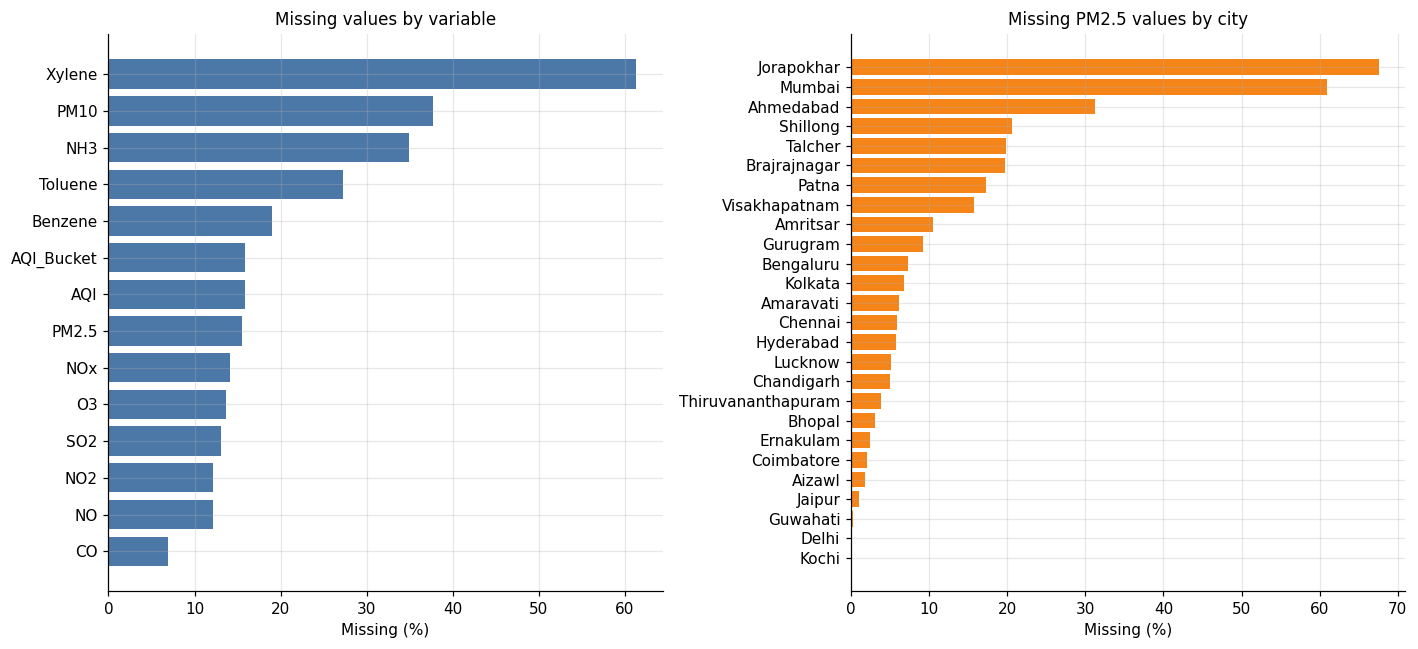

In [3]:
print(f"Records: {len(raw):,} | Columns: {raw.shape[1]} | Cities: {raw['City'].nunique()}")
print(f"Period: {raw['Date'].min().date()} to {raw['Date'].max().date()}")
display(raw.head())
display(raw.describe().T.round(2))

miss_cols = raw.drop(columns=["City", "Date"]).isna().mean().sort_values() * 100
miss_city = raw.groupby("City")["PM2.5"].apply(lambda s: s.isna().mean() * 100).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
axes[0].barh(miss_cols.index, miss_cols.values, color="#4c78a8")
axes[0].set_title("Missing values by variable")
axes[0].set_xlabel("Missing (%)")
axes[1].barh(miss_city.index, miss_city.values, color="#f58518")
axes[1].set_title("Missing PM2.5 values by city")
axes[1].set_xlabel("Missing (%)")
finish(fig, "01_raw_missing_values")

## 5. Data Cleaning

The following steps are applied in order:

1. **Scope.** Mumbai and Jorapokhar are excluded because most of their PM2.5 values are missing. AQI, AQI_Bucket, Xylene, Toluene, Benzene and NH3 are removed. AQI is derived from PM2.5 and would leak the target, and the remaining variables have excessive missing values.
2. **Chronology.** Records are sorted by city and date, and each city is re-indexed to a complete daily calendar.
3. **Error handling.** Physically implausible records are set to missing (rules listed in the cleaning log).
4. **Short-gap filling.** Gaps of up to three consecutive days are filled with the last available value. Longer gaps are not filled. Forward filling uses only past information.

In [4]:
df = (raw[~raw["City"].isin(DROP_CITIES)]
      .drop(columns=[c for c in DROP_COLS if c in raw.columns])
      .sort_values(["City", "Date"])
      .reset_index(drop=True))

frames = []
for city, g in df.groupby("City"):
    idx = pd.date_range(g["Date"].min(), g["Date"].max(), freq="D")
    g = g.set_index("Date")[POLLUTANTS].reindex(idx)
    g.index.name = "Date"
    g["City"] = city
    frames.append(g.reset_index())
daily = pd.concat(frames, ignore_index=True)
daily_raw = daily.copy()

both = daily["PM2.5"].notna() & daily["PM10"].notna()
pm25_gt_pm10 = both & (daily["PM2.5"] > daily["PM10"])
invalid_pair = both & (daily["PM2.5"] > 1.5 * daily["PM10"])
local_median = daily.groupby("City")["PM2.5"].transform(
    lambda s: s.rolling(7, center=True, min_periods=3).median())
spike = (daily["PM2.5"] > 300) & (daily["PM2.5"] > 5 * local_median)
pm10_cap = daily["PM10"] >= 1000

invalid = invalid_pair | spike
daily.loc[invalid, ["PM2.5", "PM10"]] = np.nan
daily.loc[pm10_cap, "PM10"] = np.nan
daily_clean = daily.copy()

cleaning_log = pd.DataFrame([
    ("Raw records", len(raw)),
    ("Records after excluding cities", len(df)),
    ("Records added by daily re-indexing", len(daily) - len(df)),
    ("PM2.5 above PM10 (all cases)", int(pm25_gt_pm10.sum())),
    ("PM2.5 above 1.5 x PM10: PM2.5 and PM10 set to missing", int(invalid_pair.sum())),
    ("Isolated PM2.5 spike (above 300 and 5 x local median): PM2.5 and PM10 set to missing", int(spike.sum())),
    ("PM10 at sensor cap (1000 or above): PM10 set to missing", int(pm10_cap.sum())),
    ("PM2.5 above PM10 with ratio up to 1.5: retained", int((pm25_gt_pm10 & ~invalid_pair).sum())),
    ("Records with PM2.5 invalidated", int(invalid.sum())),
], columns=["Step", "Count"])
display(cleaning_log)

,Step,Count
0,Raw records,29531
1,Records after excluding cities,26353
2,Records added by daily re-indexing,0
3,PM2.5 above PM10 (all cases),247
4,PM2.5 above 1.5 x PM10: PM2.5 and PM10 set to ...,111
5,Isolated PM2.5 spike (above 300 and 5 x local ...,19
6,PM10 at sensor cap (1000 or above): PM10 set t...,1
7,PM2.5 above PM10 with ratio up to 1.5: retained,136
8,Records with PM2.5 invalidated,126


,Missing before filling (%),Missing after filling (%)
PM2.5,10.3,9.0
PM10,36.9,35.8
NO,7.9,6.9
NO2,7.8,6.9
NOx,9.6,8.8
CO,5.8,4.7
SO2,8.7,7.6
O3,9.5,8.5


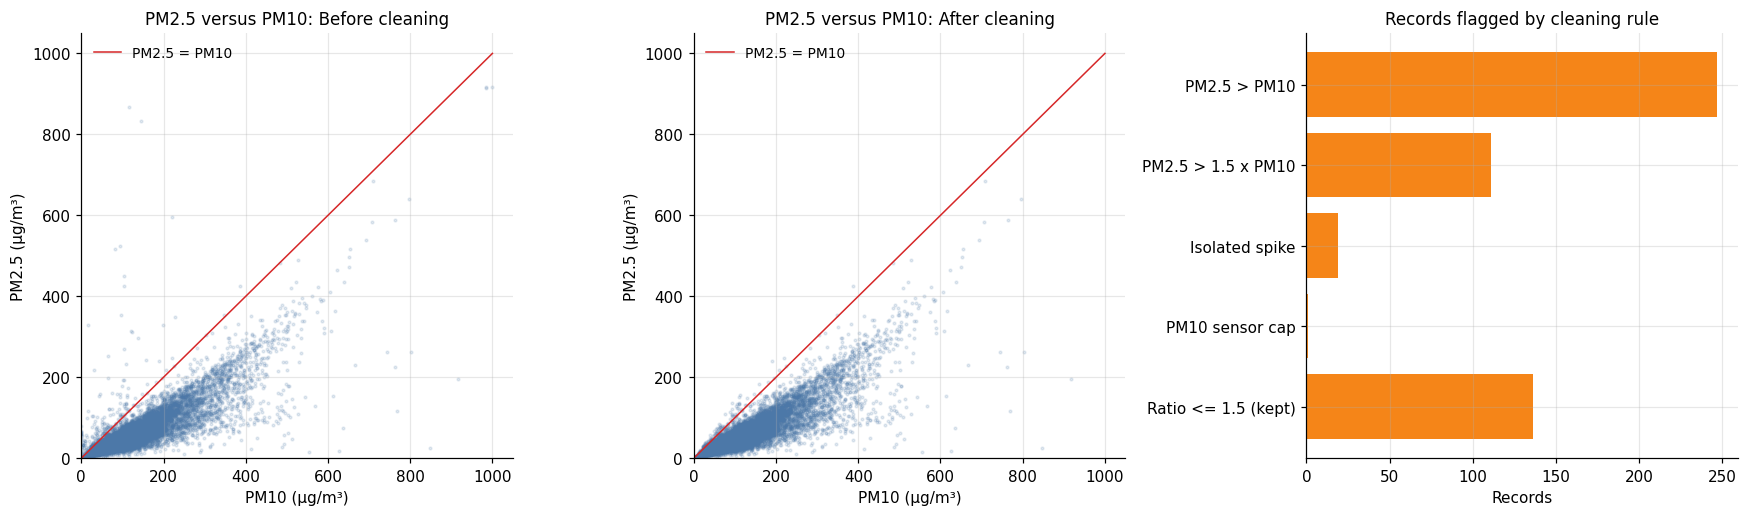

In [5]:
daily["PM2.5_obs"] = daily["PM2.5"]

def fill_short_gaps(s, limit=MAX_FILL):
    isn = s.isna()
    stretch = (isn != isn.shift()).cumsum()
    length = isn.groupby(stretch).transform("size")
    fillable = isn & (length <= limit)
    return s.where(~fillable, s.ffill())

for col in POLLUTANTS:
    daily[col] = daily.groupby("City")[col].transform(fill_short_gaps)
daily["PM10_missing"] = daily["PM10"].isna().astype(np.float32)

after_fill = pd.DataFrame({
    "Missing before filling (%)": daily_clean[POLLUTANTS].isna().mean() * 100,
    "Missing after filling (%)": daily[POLLUTANTS].isna().mean() * 100}).round(1)
display(after_fill)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, frame, title in [(axes[0], daily_raw, "Before cleaning"), (axes[1], daily_clean, "After cleaning")]:
    ax.scatter(frame["PM10"], frame["PM2.5"], s=3, alpha=0.15, color="#4c78a8")
    ax.plot([0, 1000], [0, 1000], color="#d62728", lw=1, label="PM2.5 = PM10")
    ax.set_xlim(0, 1050); ax.set_ylim(0, 1050)
    ax.set_xlabel("PM10 (µg/m³)"); ax.set_ylabel("PM2.5 (µg/m³)")
    ax.set_title(f"PM2.5 versus PM10: {title}")
    ax.legend(loc="upper left")
steps = cleaning_log.iloc[3:8].copy()
steps["Label"] = ["PM2.5 > PM10", "PM2.5 > 1.5 x PM10", "Isolated spike", "PM10 sensor cap", "Ratio <= 1.5 (kept)"]
axes[2].barh(steps["Label"], steps["Count"], color="#f58518")
axes[2].set_title("Records flagged by cleaning rule")
axes[2].set_xlabel("Records")
axes[2].invert_yaxis()
finish(fig, "02_cleaning_impact")

## 6. Exploratory Data Analysis

The cleaned data is examined for distribution, city-level differences, seasonality and relationships between pollutants. These patterns guide the choice of input features (log transformation, month encoding and a city identifier).

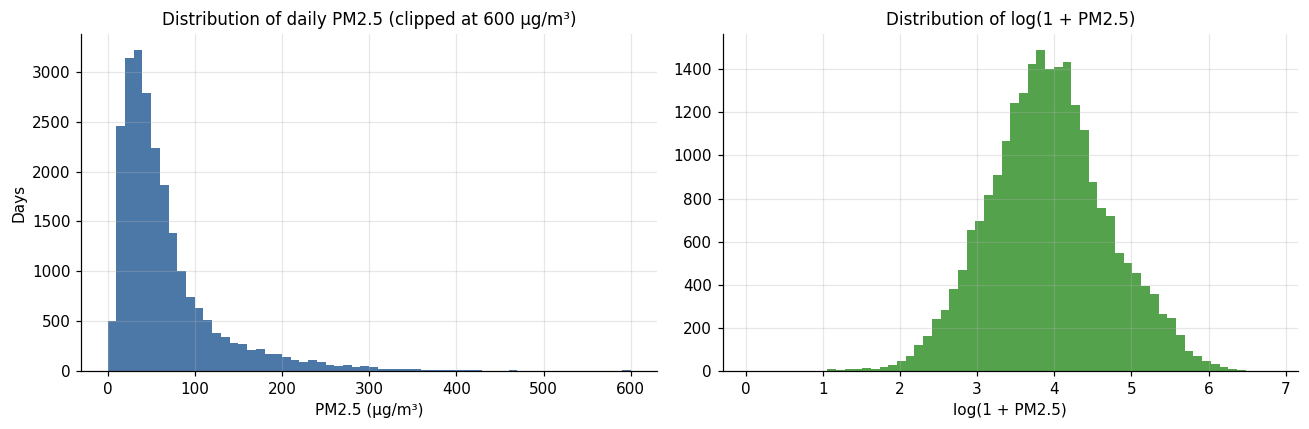

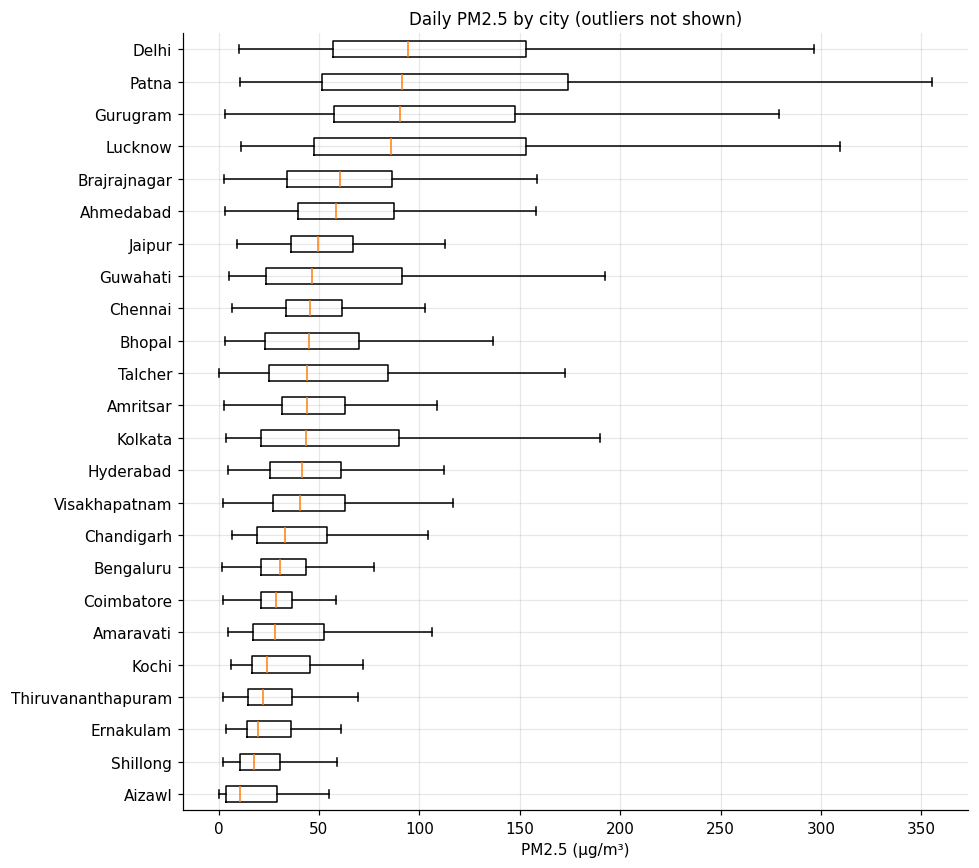

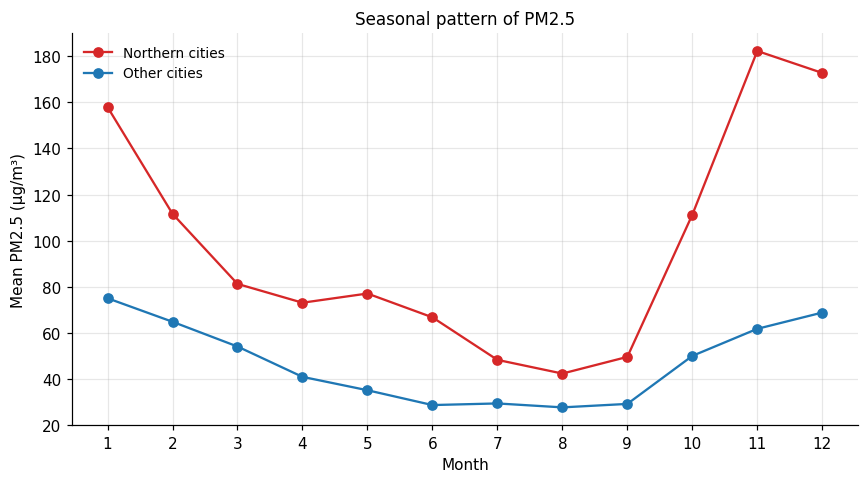

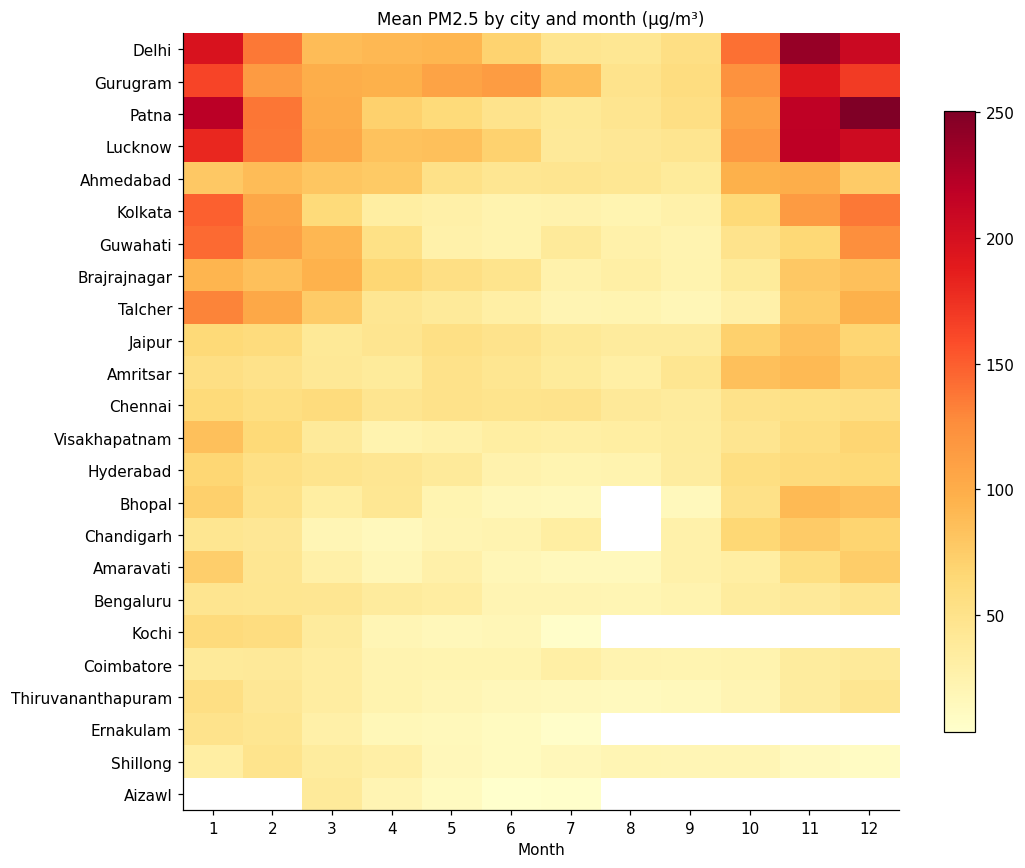

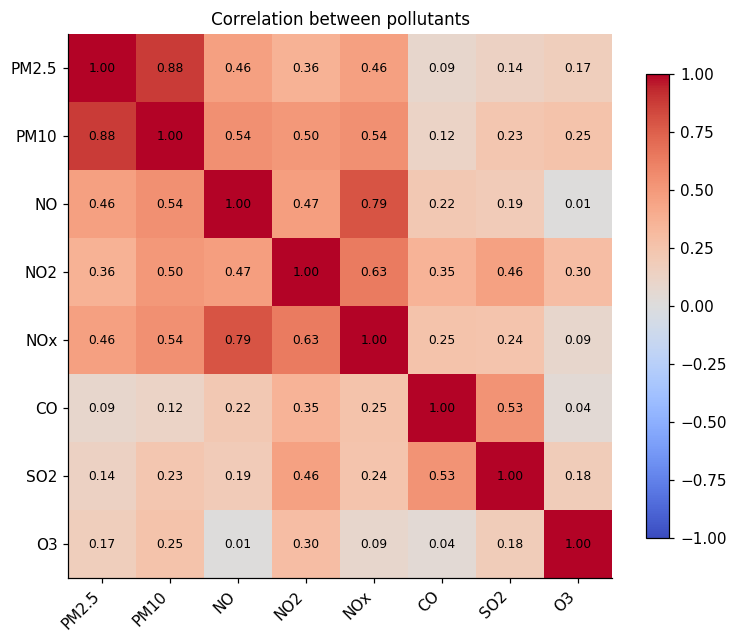

In [6]:
eda = daily.copy()
eda["Month"] = eda["Date"].dt.month
eda["Region"] = np.where(eda["City"].isin(NORTH_CITIES), "Northern cities", "Other cities")
pm = eda["PM2.5_obs"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(pm.clip(upper=600), bins=60, color="#4c78a8")
axes[0].set_title("Distribution of daily PM2.5 (clipped at 600 µg/m³)")
axes[0].set_xlabel("PM2.5 (µg/m³)"); axes[0].set_ylabel("Days")
axes[1].hist(np.log1p(pm), bins=60, color="#54a24b")
axes[1].set_title("Distribution of log(1 + PM2.5)")
axes[1].set_xlabel("log(1 + PM2.5)")
finish(fig, "03_pm25_distribution")

order = eda.groupby("City")["PM2.5_obs"].median().sort_values().index
fig, ax = plt.subplots(figsize=(9, 8))
ax.boxplot([eda.loc[eda["City"] == c, "PM2.5_obs"].dropna() for c in order], vert=False, showfliers=False)
ax.set_yticklabels(order)
ax.set_xlabel("PM2.5 (µg/m³)")
ax.set_title("Daily PM2.5 by city (outliers not shown)")
finish(fig, "04_pm25_by_city")

monthly = eda.groupby(["Region", "Month"])["PM2.5_obs"].mean().unstack(0)
fig, ax = plt.subplots(figsize=(8, 4.5))
for region, color in [("Northern cities", "#d62728"), ("Other cities", "#1f77b4")]:
    ax.plot(monthly.index, monthly[region], marker="o", color=color, label=region)
ax.set_xticks(range(1, 13))
ax.set_xlabel("Month"); ax.set_ylabel("Mean PM2.5 (µg/m³)")
ax.set_title("Seasonal pattern of PM2.5")
ax.legend()
finish(fig, "05_seasonality")

heat = eda.pivot_table(index="City", columns="Month", values="PM2.5_obs", aggfunc="mean")
heat = heat.loc[heat.mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(heat.values, aspect="auto", cmap="YlOrRd")
ax.set_xticks(range(12)); ax.set_xticklabels(range(1, 13))
ax.set_yticks(range(len(heat))); ax.set_yticklabels(heat.index)
ax.grid(False)
ax.set_xlabel("Month"); ax.set_title("Mean PM2.5 by city and month (µg/m³)")
fig.colorbar(im, ax=ax, shrink=0.8)
finish(fig, "06_city_month_heatmap")

corr = daily[POLLUTANTS].corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(POLLUTANTS))); ax.set_xticklabels(POLLUTANTS, rotation=45, ha="right")
ax.set_yticks(range(len(POLLUTANTS))); ax.set_yticklabels(POLLUTANTS)
ax.grid(False)
for i in range(len(POLLUTANTS)):
    for j in range(len(POLLUTANTS)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Correlation between pollutants")
fig.colorbar(im, ax=ax, shrink=0.8)
finish(fig, "07_correlation")

## 7. Data Preparation

**Chronological split.** Each city is divided by time into 70% training, 15% validation and 15% test periods. No random shuffling is used, so every model is evaluated on days later than any training day.

**Training-only statistics.** Missing-value medians, log transformation parameters (mean and standard deviation) are computed from training rows only and then applied to all rows. Remaining gaps are filled with the training median, and a PM10-missing indicator is provided to the models.

**Features.** For each day: eight pollutants (log-transformed and standardised), a PM10-missing indicator, and the month encoded as sine and cosine. A seven-day window of these 11 channels forms one sample, together with the city identifier.

**Targets.** PM2.5 at 1, 3 and 7 days ahead, expressed as the change from the current day's PM2.5. A window is retained only if the current PM2.5 and all three target values were actually measured.

**Leakage control.** A window is assigned to a split by the date of its last target. Windows whose targets would cross a split boundary are removed, so no target date appears in more than one split.

In [7]:
daily["row"] = daily.groupby("City").cumcount()
daily["n"] = daily.groupby("City")["row"].transform("size")
train_end = (daily["n"] * TRAIN_FRAC).astype(int)
val_end = (daily["n"] * (TRAIN_FRAC + VAL_FRAC)).astype(int)
daily["period"] = np.select([daily["row"] < train_end, daily["row"] < val_end], [0, 1], 2)
daily["Split"] = daily["period"].map({0: "train", 1: "validation", 2: "test"})

train_rows = daily["period"] == 0
train_median = daily.loc[train_rows, POLLUTANTS].median()
feat = np.log1p(daily[POLLUTANTS].fillna(train_median).clip(lower=0))
feat_mean = feat[train_rows].mean()
feat_std = feat[train_rows].std()
scaled = (feat - feat_mean) / feat_std

month = daily["Date"].dt.month
scaled["PM10_missing"] = daily["PM10_missing"]
scaled["month_sin"] = np.sin(2 * np.pi * month / 12)
scaled["month_cos"] = np.cos(2 * np.pi * month / 12)
CHANNELS = list(scaled.columns)

cities = sorted(daily["City"].unique())
city_to_id = {c: i for i, c in enumerate(cities)}
N_CITIES = len(cities)

X_list, y_list, base_list, pm_win_list = [], [], [], []
cid_list, date_list, split_list = [], [], []
removed_boundary = 0

for city, g in daily.groupby("City"):
    vals = scaled.loc[g.index, CHANNELS].to_numpy(np.float32)
    obs = g["PM2.5_obs"].to_numpy()
    filled = g["PM2.5"].to_numpy()
    period = g["period"].to_numpy()
    dates = g["Date"].to_numpy()
    for i in range(WINDOW - 1, len(g) - HMAX):
        targets = [obs[i + h] for h in HORIZONS]
        if np.isnan(obs[i]) or np.isnan(targets).any():
            continue
        if period[i + 1] != period[i + HMAX]:
            removed_boundary += 1
            continue
        X_list.append(vals[i - WINDOW + 1:i + 1])
        y_list.append(targets)
        base_list.append(obs[i])
        pm_win_list.append(filled[i - WINDOW + 1:i + 1])
        cid_list.append(city_to_id[city])
        date_list.append(dates[i])
        split_list.append(period[i + HMAX])

X = np.stack(X_list).astype(np.float32)
y_abs = np.array(y_list, dtype=np.float32)
base = np.array(base_list, dtype=np.float32)
pm_win = np.stack(pm_win_list).astype(np.float32)
city_id = np.array(cid_list)
win_date = np.array(date_list)
split = np.array(split_list)

y_res = y_abs - base[:, None]
tr, va, te = split == 0, split == 1, split == 2
y_scale = np.maximum(y_res[tr].std(axis=0), 1e-6).astype(np.float32)

print(f"Input tensor: {X.shape} (samples, days, channels) | Targets: {y_abs.shape}")
print(f"Channels: {CHANNELS}")
print(f"Windows: training {tr.sum():,} | validation {va.sum():,} | test {te.sum():,}")
print(f"Windows removed at split boundaries: {removed_boundary}")
print(f"Target scale (training standard deviation of change, µg/m³): {np.round(y_scale, 1)}")

clean_export = daily[["City", "Date"] + POLLUTANTS + ["PM2.5_obs", "PM10_missing", "Split"]].rename(
    columns={"PM2.5_obs": "PM2.5_measured"})
clean_export.to_csv(os.path.join(OUT_DIR, "data", "clean", "clean_daily.csv"), index=False)
np.savez_compressed(os.path.join(OUT_DIR, "data", "clean", "pm25_windows.npz"), X=X, y_abs=y_abs, base=base,
                    pm_win=pm_win, city_id=city_id, split=split, win_date=win_date.astype("datetime64[D]").astype(str),
                    y_scale=y_scale, cities=np.array(cities), channels=np.array(CHANNELS))

Input tensor: (21981, 7, 11) (samples, days, channels) | Targets: (21981, 3)
Channels: ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'CO', 'SO2', 'O3', 'PM10_missing', 'month_sin', 'month_cos']
Windows: training 14,753 | validation 3,633 | test 3,595
Windows removed at split boundaries: 263
Target scale (training standard deviation of change, µg/m³): [33.6 44.5 49.7]


Split,Training,Validation,Test,Total
City,,,,
Aizawl,66,10,8,84
Ernakulam,96,18,12,126
Kochi,100,18,19,137
Shillong,115,9,37,161
Bhopal,181,35,38,254
Chandigarh,184,40,40,264
Coimbatore,243,42,47,332
Guwahati,332,69,70,471
Talcher,415,109,82,606


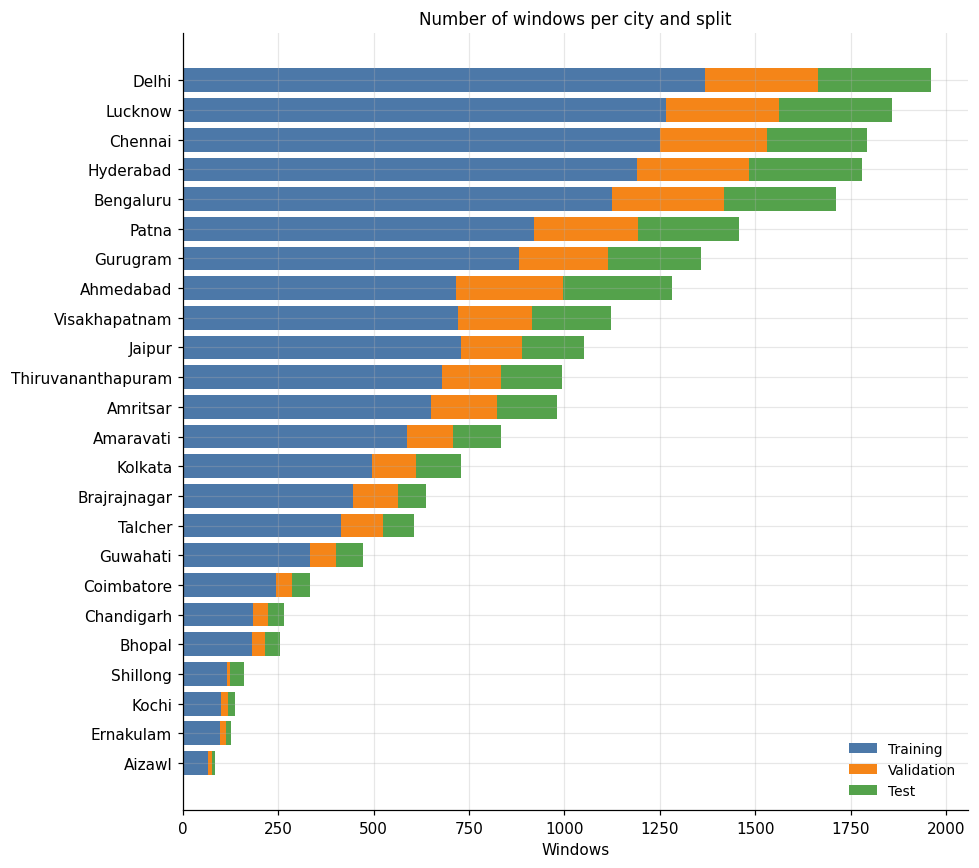

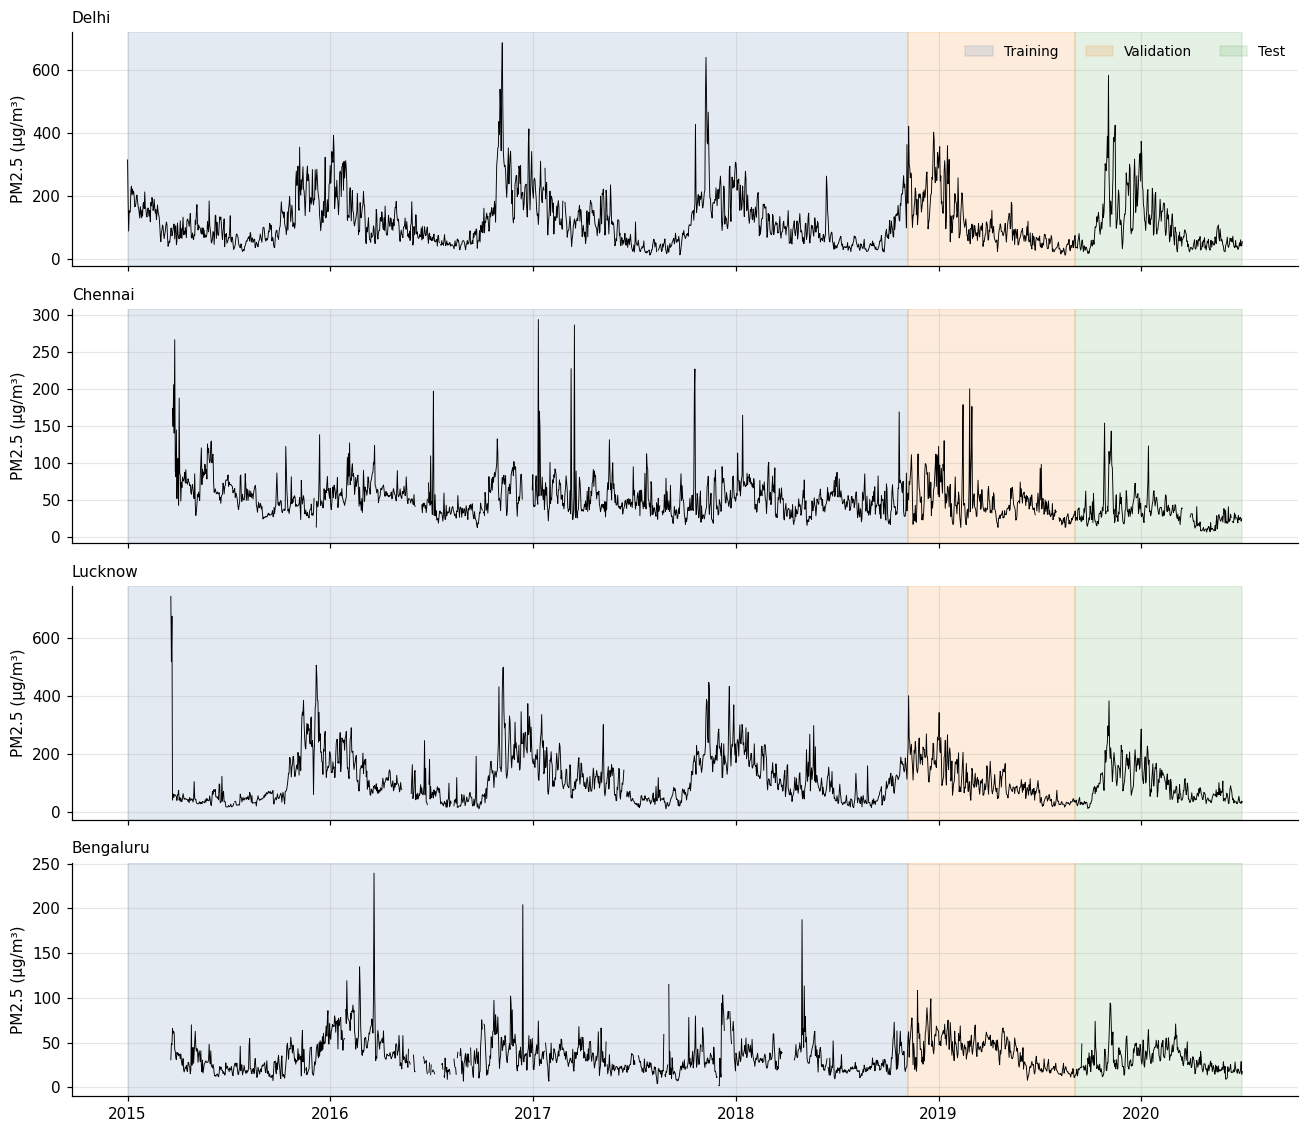

In [8]:
counts = (pd.DataFrame({"City": [cities[i] for i in city_id], "Split": split})
          .pivot_table(index="City", columns="Split", aggfunc="size", fill_value=0)
          .rename(columns={0: "Training", 1: "Validation", 2: "Test"}))
counts["Total"] = counts.sum(axis=1)
display(counts.sort_values("Total"))

fig, ax = plt.subplots(figsize=(9, 8))
ordered = counts.sort_values("Total")
left = np.zeros(len(ordered))
for col, color in [("Training", "#4c78a8"), ("Validation", "#f58518"), ("Test", "#54a24b")]:
    ax.barh(ordered.index, ordered[col], left=left, color=color, label=col)
    left += ordered[col].to_numpy()
ax.set_xlabel("Windows"); ax.set_title("Number of windows per city and split")
ax.legend()
finish(fig, "08_windows_per_city")

fig, axes = plt.subplots(len(PLOT_CITIES) + 2, 1, figsize=(12, 2.6 * (len(PLOT_CITIES) + 2)), sharex=True)
span_colors = {"train": "#4c78a8", "validation": "#f58518", "test": "#54a24b"}
for ax, city in zip(axes, PLOT_CITIES + ["Lucknow", "Bengaluru"]):
    g = daily[daily["City"] == city]
    ax.plot(g["Date"], g["PM2.5_obs"], lw=0.6, color="black")
    for label, part in g.groupby("Split"):
        ax.axvspan(part["Date"].min(), part["Date"].max(), color=span_colors[label], alpha=0.15, label=label)
    ax.set_ylabel("PM2.5 (µg/m³)"); ax.set_title(city, loc="left", fontsize=10)
handles, labels = axes[0].get_legend_handles_labels()
uniq = dict(zip(labels, handles))
ordered_labels = [k for k in ["train", "validation", "test"] if k in uniq]
axes[0].legend([uniq[k] for k in ordered_labels], ["Training", "Validation", "Test"][:len(ordered_labels)], ncol=3, loc="upper right")
finish(fig, "09_split_timeline")

## 8. Reference Methods

Two forecasting rules that require no training are evaluated on the same test windows. They provide a floor for judging whether the neural models add value.

- **Persistence:** the forecast equals the current day's PM2.5.
- **7-day average:** the forecast equals the mean PM2.5 of the previous seven days.

The MLP remains the baseline model for comparing architectures.

In [9]:
def error_metrics(y_true, y_pred):
    err = (y_pred - y_true).astype(np.float64)
    return np.sqrt((err ** 2).mean(axis=0)), np.abs(err).mean(axis=0)

persist = np.repeat(base[:, None], len(HORIZONS), axis=1)
avg7 = np.repeat(np.nanmean(pm_win, axis=1)[:, None], len(HORIZONS), axis=1)
reference = {}
if INCLUDE_REFERENCE:
    for name, pred in [("Persistence", persist), ("7-day average", avg7)]:
        rmse, mae = error_metrics(y_abs[te], pred[te])
        reference[name] = {"rmse": rmse, "mae": mae}
    display(pd.DataFrame({n: np.concatenate([v["rmse"], v["mae"]]) for n, v in reference.items()},
                         index=[f"RMSE t+{h}" for h in HORIZONS] + [f"MAE t+{h}" for h in HORIZONS]).round(2))

,Persistence,7-day average
RMSE t+1,23.41,30.17
RMSE t+3,36.64,34.63
RMSE t+7,42.19,36.24
MAE t+1,12.69,16.76
MAE t+3,20.10,19.23
MAE t+7,22.88,20.63


## 9. Model Architectures

Each architecture follows widely used design conventions and is constrained to at most 60,000 trainable parameters, so that differences in results reflect architecture and not capacity. All models output three values (the scaled change in PM2.5 at 1, 3 and 7 days).

| Model | Standard components |
|---|---|
| MLP | Fully connected layers with batch normalisation, ReLU activation and dropout; city supplied as a one-hot vector |
| 1D-CNN | Stacked one-dimensional convolutions with batch normalisation and ReLU, global average and max pooling, dense head; city embedding |
| LSTM/GRU | Stacked recurrent layers with inter-layer dropout, last hidden state, dense head; city embedding; cell type (LSTM or GRU) selected by validation |
| Transformer | Linear input projection, sinusoidal positional encoding, pre-layer-normalisation encoder with multi-head self-attention and GELU feed-forward blocks, mean pooling, dense head; city embedding |

In [10]:
class MLP(nn.Module):
    def __init__(self, in_dim, hidden, dropout, out_dim=3):
        super().__init__()
        layers, d = [], in_dim
        for h in hidden:
            layers += [nn.Linear(d, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(dropout)]
            d = h
        layers.append(nn.Linear(d, out_dim))
        self.net = nn.Sequential(*layers)

    def forward(self, x, city):
        return self.net(x)


class CNN1D(nn.Module):
    def __init__(self, in_ch, n_cities, channels, n_layers, kernel, head_hidden, dropout, emb_dim=8, out_dim=3):
        super().__init__()
        blocks, c = [], in_ch
        for _ in range(n_layers):
            blocks += [nn.Conv1d(c, channels, kernel, padding=kernel // 2), nn.BatchNorm1d(channels), nn.ReLU()]
            c = channels
        self.conv = nn.Sequential(*blocks)
        self.emb = nn.Embedding(n_cities, emb_dim)
        self.head = nn.Sequential(nn.Linear(2 * channels + emb_dim, head_hidden), nn.ReLU(),
                                  nn.Dropout(dropout), nn.Linear(head_hidden, out_dim))

    def forward(self, x, city):
        z = self.conv(x)
        z = torch.cat([z.mean(dim=2), z.amax(dim=2)], dim=1)
        return self.head(torch.cat([z, self.emb(city)], dim=1))


class RNNForecaster(nn.Module):
    def __init__(self, in_ch, n_cities, cell, hidden, layers, head_hidden, dropout, emb_dim=8, out_dim=3):
        super().__init__()
        rnn_cls = nn.LSTM if cell == "LSTM" else nn.GRU
        self.rnn = rnn_cls(in_ch, hidden, num_layers=layers, batch_first=True,
                           dropout=dropout if layers > 1 else 0.0)
        self.emb = nn.Embedding(n_cities, emb_dim)
        self.head = nn.Sequential(nn.Linear(hidden + emb_dim, head_hidden), nn.ReLU(),
                                  nn.Dropout(dropout), nn.Linear(head_hidden, out_dim))

    def forward(self, x, city):
        out, _ = self.rnn(x)
        return self.head(torch.cat([out[:, -1], self.emb(city)], dim=1))


class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=64):
        super().__init__()
        pos = torch.arange(max_len).unsqueeze(1).float()
        div = torch.exp(torch.arange(0, d_model, 2).float() * (-np.log(10000.0) / d_model))
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, : x.size(1)]


class TransformerForecaster(nn.Module):
    def __init__(self, in_ch, n_cities, d_model, heads, layers, ff_mult, head_hidden, dropout, emb_dim=8, out_dim=3):
        super().__init__()
        self.proj = nn.Linear(in_ch, d_model)
        self.pos = PositionalEncoding(d_model)
        layer = nn.TransformerEncoderLayer(d_model, heads, dim_feedforward=ff_mult * d_model, dropout=dropout,
                                           activation="gelu", batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, layers, norm=nn.LayerNorm(d_model), enable_nested_tensor=False)
        self.emb = nn.Embedding(n_cities, emb_dim)
        self.head = nn.Sequential(nn.Linear(d_model + emb_dim, head_hidden), nn.ReLU(),
                                  nn.Dropout(dropout), nn.Linear(head_hidden, out_dim))

    def forward(self, x, city):
        z = self.encoder(self.pos(self.proj(x)))
        return self.head(torch.cat([z.mean(dim=1), self.emb(city)], dim=1))


N_CH = X.shape[2]
onehot = np.eye(N_CITIES, dtype=np.float32)[city_id]
n_poll = len(POLLUTANTS) + 1
seq = torch.tensor(X, device=DEVICE)
INPUTS = {
    "MLP": torch.tensor(np.concatenate([X[:, :, :n_poll].reshape(len(X), -1), X[:, -1, n_poll:], onehot], axis=1), device=DEVICE),
    "1D-CNN": torch.tensor(np.transpose(X, (0, 2, 1)).copy(), device=DEVICE),
    "LSTM/GRU": seq,
    "Transformer": seq,
}

def build_model(name, cfg):
    if name == "MLP":
        return MLP(INPUTS["MLP"].shape[1], cfg["hidden"], cfg["dropout"])
    if name == "1D-CNN":
        return CNN1D(N_CH, N_CITIES, cfg["channels"], cfg["n_layers"], cfg["kernel"], cfg["head_hidden"], cfg["dropout"])
    if name == "LSTM/GRU":
        return RNNForecaster(N_CH, N_CITIES, cfg["cell"], cfg["hidden"], cfg["layers"], cfg["head_hidden"], cfg["dropout"])
    return TransformerForecaster(N_CH, N_CITIES, cfg["d_model"], cfg["heads"], cfg["layers"], cfg["ff_mult"],
                                 cfg["head_hidden"], cfg["dropout"])

def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def pick(rng, options):
    return options[int(rng.integers(len(options)))]

def sample_config(name, rng):
    cfg = {"lr": float(10 ** rng.uniform(np.log10(5e-4), np.log10(5e-3))),
           "weight_decay": float(pick(rng, [1e-5, 1e-4, 1e-3, 1e-2])),
           "dropout": float(pick(rng, [0.0, 0.1, 0.2, 0.3])),
           "batch_size": int(pick(rng, [128, 256]))}
    if name == "MLP":
        cfg["hidden"] = list(pick(rng, [(64, 32), (128, 64), (192, 96), (256, 128), (128, 64, 32)]))
    elif name == "1D-CNN":
        cfg.update(channels=int(pick(rng, [16, 32, 48])), n_layers=int(pick(rng, [2, 3])),
                   kernel=int(pick(rng, [3, 5])), head_hidden=int(pick(rng, [32, 64, 128])))
    elif name == "LSTM/GRU":
        cfg.update(cell=pick(rng, ["LSTM", "GRU"]), hidden=int(pick(rng, [32, 48, 64])),
                   layers=int(pick(rng, [1, 2])), head_hidden=int(pick(rng, [32, 64])))
    else:
        cfg.update(d_model=int(pick(rng, [32, 48])), heads=int(pick(rng, [2, 4])), layers=int(pick(rng, [1, 2, 3])),
                   ff_mult=int(pick(rng, [2, 4])), head_hidden=int(pick(rng, [32, 64])), warmup=3)
    return cfg

def sample_valid_config(name, rng):
    for _ in range(500):
        cfg = sample_config(name, rng)
        n = count_params(build_model(name, cfg))
        if n <= PARAM_CAP:
            return cfg, n
    raise RuntimeError(f"No configuration within the parameter limit was found for {name}.")

## 10. Training and Evaluation Procedure

All models are trained with the same procedure:

- **Loss:** mean squared error on the scaled change in PM2.5, summed over the three horizons.
- **Optimiser:** AdamW with weight decay, gradient clipping at a norm of 1.0, and automatic mixed precision on GPU.
- **Learning rate:** reduced by half when the validation loss does not improve for four epochs (linear warm-up for the Transformer).
- **Early stopping:** training stops when the validation loss has not improved for 12 epochs, and the best epoch is restored.
- **Per-epoch monitoring:** loss, R² and accuracy are computed on the full training and validation sets in evaluation mode. Accuracy is the share of days on which the predicted CPCB air quality category (Good 0 to 30, Satisfactory 31 to 60, Moderate 61 to 90, Poor 91 to 120, Very Poor 121 to 250, Severe above 250 µg/m³) equals the observed category. R² is computed on PM2.5 concentrations in µg/m³.

In [11]:
city_t = torch.tensor(city_id, dtype=torch.long, device=DEVICE)
y_t = torch.tensor(y_res / y_scale, dtype=torch.float32, device=DEVICE)
base_t = torch.tensor(base, dtype=torch.float32, device=DEVICE)
yabs_t = torch.tensor(y_abs, dtype=torch.float32, device=DEVICE)
scale_t = torch.tensor(y_scale, dtype=torch.float32, device=DEVICE)
edges_t = torch.tensor(BAND_EDGES, dtype=torch.float32, device=DEVICE)
idx_tr, idx_va, idx_te = [torch.tensor(np.where(m)[0], device=DEVICE) for m in (tr, va, te)]
loss_fn = nn.MSELoss()

@torch.no_grad()
def predict_scaled(model, x_all, idx):
    model.eval()
    chunks = [model(x_all[idx[i:i + 4096]], city_t[idx[i:i + 4096]]) for i in range(0, len(idx), 4096)]
    return torch.cat(chunks).float()

def to_concentration(out, idx):
    return torch.clamp(base_t[idx, None] + out * scale_t, min=0)

@torch.no_grad()
def split_metrics(out, idx):
    pred, true = to_concentration(out, idx), yabs_t[idx]
    sse = ((pred - true) ** 2).sum(0)
    sst = ((true - true.mean(0)) ** 2).sum(0)
    acc = (torch.bucketize(pred, edges_t) == torch.bucketize(true, edges_t)).float().mean(0)
    return {"loss": float(loss_fn(out, y_t[idx])), "r2": (1 - sse / sst).cpu().numpy(),
            "acc": acc.cpu().numpy(), "rmse": torch.sqrt(((pred - true) ** 2).mean(0)).cpu().numpy()}

def predict_concentration(model, name, idx):
    return to_concentration(predict_scaled(model, INPUTS[name], idx), idx).cpu().numpy()

HIST_KEYS = ["lr", "train_loss", "val_loss", "train_acc", "val_acc", "train_r2", "val_r2", "train_acc_h", "val_acc_h"]

def fit(name, cfg, seed):
    set_seed(seed)
    model = build_model(name, cfg).to(DEVICE)
    x_all = INPUTS[name]
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=4, min_lr=1e-6)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    gen = torch.Generator().manual_seed(seed)
    warmup = cfg.get("warmup", 0)
    hist = {k: [] for k in HIST_KEYS}
    best = {"loss": float("inf"), "state": None, "epoch": 0, "val_rmse": None}
    wait, start = 0, time.time()
    for epoch in range(1, MAX_EPOCHS + 1):
        if epoch <= warmup:
            for group in opt.param_groups:
                group["lr"] = cfg["lr"] * epoch / warmup
        model.train()
        perm = idx_tr[torch.randperm(len(idx_tr), generator=gen).to(DEVICE)]
        for s in range(0, len(perm), cfg["batch_size"]):
            b = perm[s:s + cfg["batch_size"]]
            if len(b) < 2:
                continue
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=AUTOCAST_DEVICE, dtype=torch.float16, enabled=USE_AMP):
                out = model(x_all[b], city_t[b])
            loss = loss_fn(out.float(), y_t[b])
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt)
            scaler.update()
        mt = split_metrics(predict_scaled(model, x_all, idx_tr), idx_tr)
        mv = split_metrics(predict_scaled(model, x_all, idx_va), idx_va)
        if epoch > warmup:
            sched.step(mv["loss"])
        hist["lr"].append(opt.param_groups[0]["lr"])
        hist["train_loss"].append(mt["loss"]); hist["val_loss"].append(mv["loss"])
        hist["train_acc"].append(float(mt["acc"].mean()) * 100); hist["val_acc"].append(float(mv["acc"].mean()) * 100)
        hist["train_r2"].append(float(mt["r2"].mean())); hist["val_r2"].append(float(mv["r2"].mean()))
        hist["train_acc_h"].append(mt["acc"] * 100); hist["val_acc_h"].append(mv["acc"] * 100)
        if mv["loss"] < best["loss"] - 1e-6:
            best.update(loss=mv["loss"], state=copy.deepcopy(model.state_dict()), epoch=epoch, val_rmse=mv["rmse"])
            wait = 0
        else:
            wait += 1
            if wait >= PATIENCE:
                break
    model.load_state_dict(best["state"])
    return {"model": model, "history": hist, "best_epoch": best["epoch"], "val_rmse": best["val_rmse"],
            "seconds": time.time() - start}

## 11. Hyperparameter Search and Final Training

For each architecture, a random search evaluates a fixed number of configurations that satisfy the parameter limit (search space: learning rate, weight decay, dropout, batch size and architecture-specific dimensions). Configurations are ranked by the mean validation RMSE across the three horizons. The test set is not used during the search.

The best configuration for each architecture is then trained with three different random seeds. Test results are computed once, from the weights at the best validation epoch of each run.

In [12]:
search_log, runs, best_cfg = [], {}, {}
t_total = time.time()

for m_idx, name in enumerate(MODEL_NAMES):
    rng = np.random.default_rng(SEARCH_SEED + m_idx)
    best_val, best_n = float("inf"), None
    print(f"{name}: hyperparameter search ({N_TRIALS} configurations)")
    for trial in range(1, N_TRIALS + 1):
        cfg, n_par = sample_valid_config(name, rng)
        res = fit(name, cfg, seed=SEARCH_SEED)
        val_rmse = float(res["val_rmse"].mean())
        search_log.append({"Model": name, "Trial": trial, "Parameters": n_par, "Validation RMSE": val_rmse,
                           "Best epoch": res["best_epoch"], "Seconds": round(res["seconds"], 1), "Configuration": json.dumps(cfg)})
        print(f"  trial {trial}: parameters {n_par:,} | validation RMSE {val_rmse:.3f} | epochs {res['best_epoch']} | {res['seconds']:.0f}s")
        if val_rmse < best_val:
            best_val, best_cfg[name], best_n = val_rmse, cfg, n_par
        del res
    print(f"  selected configuration: {best_cfg[name]}")

    store = {"params": best_n, "histories": [], "rmse": [], "mae": [], "test_pred": [], "seconds": [], "best_epoch": []}
    for seed in FINAL_SEEDS:
        res = fit(name, best_cfg[name], seed=seed)
        pred = predict_concentration(res["model"], name, idx_te)
        rmse, mae = error_metrics(y_abs[te], pred)
        store["histories"].append(res["history"]); store["rmse"].append(rmse); store["mae"].append(mae)
        store["test_pred"].append(pred); store["seconds"].append(res["seconds"]); store["best_epoch"].append(res["best_epoch"])
        print(f"  final run, seed {seed}: epochs {len(res['history']['val_loss'])} (best {res['best_epoch']}) | "
              f"test RMSE {np.round(rmse, 2)} | {res['seconds']:.0f}s")
        del res
    for k in ("rmse", "mae", "test_pred"):
        store[k] = np.stack(store[k])
    runs[name] = store
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

print(f"Total training time: {(time.time() - t_total) / 60:.1f} minutes")
display(pd.DataFrame(search_log).drop(columns="Configuration").round(3))

MLP: hyperparameter search (6 configurations)
  trial 1: parameters 8,131 | validation RMSE 28.297 | epochs 13 | 13s
  trial 2: parameters 22,403 | validation RMSE 28.725 | epochs 20 | 7s
  trial 3: parameters 36,675 | validation RMSE 28.218 | epochs 12 | 4s
  trial 4: parameters 8,131 | validation RMSE 28.409 | epochs 22 | 6s
  trial 5: parameters 57,091 | validation RMSE 29.129 | epochs 5 | 3s
  trial 6: parameters 36,675 | validation RMSE 28.263 | epochs 13 | 9s
  selected configuration: {'lr': 0.002021183667077895, 'weight_decay': 0.01, 'dropout': 0.2, 'batch_size': 256, 'hidden': [192, 96]}
  final run, seed 0: epochs 24 (best 12) | test RMSE [22.18 31.64 34.1 ] | 4s
  final run, seed 1: epochs 19 (best 7) | test RMSE [22.09 31.18 34.16] | 4s
  final run, seed 2: epochs 34 (best 22) | test RMSE [22.   31.9  35.26] | 7s
1D-CNN: hyperparameter search (6 configurations)
  trial 1: parameters 5,187 | validation RMSE 28.766 | epochs 11 | 15s
  trial 2: parameters 5,267 | validation RMS

,Model,Trial,Parameters,Validation RMSE,Best epoch,Seconds
0,MLP,1,8131,28.297,13,12.7
1,MLP,2,22403,28.725,20,7.0
2,MLP,3,36675,28.218,12,4.3
3,MLP,4,8131,28.409,22,6.1
4,MLP,5,57091,29.129,5,2.9
5,MLP,6,36675,28.263,13,8.8
6,1D-CNN,1,5187,28.766,11,14.9
7,1D-CNN,2,5267,28.908,21,8.0
8,1D-CNN,3,12547,29.621,22,9.7
9,1D-CNN,4,15891,28.885,6,8.5


## 12. Results

Test-set RMSE and MAE (µg/m³) are reported for each architecture at the three forecast horizons as mean ± standard deviation over three seeds. The change relative to the MLP baseline is positive when a model is more accurate than the MLP. Persistence and the 7-day average are included as reference rows.

In [13]:
all_rows = list(MODEL_NAMES) + list(reference)
labels = {BASELINE: f"{BASELINE} (baseline)"}

def row_stats(name):
    if name in runs:
        r = runs[name]
        return r["rmse"].mean(0), r["rmse"].std(0), r["mae"].mean(0), r["mae"].std(0)
    zeros = np.zeros(len(HORIZONS))
    return reference[name]["rmse"], zeros, reference[name]["mae"], zeros

def fmt(mean, sd):
    return f"{mean:.2f} ± {sd:.2f}" if sd > 0 else f"{mean:.2f}"

columns = pd.MultiIndex.from_product([[f"t+{h} days" for h in HORIZONS], ["RMSE", "MAE"]])
table = pd.DataFrame(index=[labels.get(n, n) for n in all_rows], columns=columns)
numeric_rows = []
for n in all_rows:
    rm, rs, am, a_s = row_stats(n)
    for j, h in enumerate(HORIZONS):
        table.loc[labels.get(n, n), (f"t+{h} days", "RMSE")] = fmt(rm[j], rs[j])
        table.loc[labels.get(n, n), (f"t+{h} days", "MAE")] = fmt(am[j], a_s[j])
        numeric_rows.append({"Model": n, "Horizon (days)": h, "RMSE mean": rm[j], "RMSE std": rs[j],
                             "MAE mean": am[j], "MAE std": a_s[j]})
results_numeric = pd.DataFrame(numeric_rows)
print("Test-set error (µg/m³)")
display(table)

base_rmse = runs[BASELINE]["rmse"].mean(0)
vs_baseline = pd.DataFrame({n: (base_rmse - runs[n]["rmse"].mean(0)) / base_rmse * 100
                            for n in MODEL_NAMES if n != BASELINE},
                           index=[f"t+{h} days" for h in HORIZONS]).round(1)
print(f"RMSE change relative to the {BASELINE} baseline (%, positive = more accurate than {BASELINE})")
display(vs_baseline)

if INCLUDE_REFERENCE:
    best_ref = np.minimum(reference["Persistence"]["rmse"], reference["7-day average"]["rmse"])
    gain_ref = pd.DataFrame({n: (best_ref - runs[n]["rmse"].mean(0)) / best_ref * 100 for n in MODEL_NAMES},
                            index=[f"t+{h} days" for h in HORIZONS]).round(1)
    print("RMSE improvement over the better of persistence and the 7-day average (%)")
    display(gain_ref)

param_table = pd.DataFrame({
    "Model": MODEL_NAMES,
    "Parameters": [runs[n]["params"] for n in MODEL_NAMES],
    "Mean best epoch": [np.mean(runs[n]["best_epoch"]) for n in MODEL_NAMES],
    "Mean training time per run (s)": [np.mean(runs[n]["seconds"]) for n in MODEL_NAMES],
    "Selected configuration": [json.dumps(best_cfg[n]) for n in MODEL_NAMES]}).round(1)
display(param_table.drop(columns="Selected configuration"))

ensemble_rows = []
for n in MODEL_NAMES:
    rm, am = error_metrics(y_abs[te], runs[n]["test_pred"].mean(0))
    for j, h in enumerate(HORIZONS):
        ensemble_rows.append({"Model": n, "Horizon (days)": h, "RMSE": rm[j], "MAE": am[j]})
ensemble_df = pd.DataFrame(ensemble_rows)
print("Supplementary: error of the average prediction of the three seeds")
display(ensemble_df.pivot(index="Model", columns="Horizon (days)", values="RMSE").round(2))

for j, h in enumerate(HORIZONS):
    best_name = min(MODEL_NAMES, key=lambda n: runs[n]["rmse"].mean(0)[j])
    print(f"Lowest mean RMSE at t+{h}: {best_name} ({runs[best_name]['rmse'].mean(0)[j]:.2f} µg/m³)")

Test-set error (µg/m³)


t+1 days                    t+3 days                \
                        RMSE           MAE          RMSE           MAE   
MLP (baseline)  22.09 ± 0.07  12.51 ± 0.12  31.57 ± 0.30  18.32 ± 0.36   
1D-CNN          22.24 ± 0.16  12.58 ± 0.12  31.77 ± 0.66  18.53 ± 0.27   
LSTM/GRU        21.85 ± 0.08  12.32 ± 0.13  30.72 ± 0.22  17.65 ± 0.22   
Transformer     22.13 ± 0.06  12.57 ± 0.20  31.10 ± 0.44  17.95 ± 0.51   
Persistence            23.41         12.69         36.64         20.10   
7-day average          30.17         16.76         34.63         19.23   

                    t+7 days                
                        RMSE           MAE  
MLP (baseline)  34.51 ± 0.54  20.69 ± 0.63  
1D-CNN          34.64 ± 0.69  21.05 ± 0.17  
LSTM/GRU        33.49 ± 0.53  19.73 ± 0.36  
Transformer     34.04 ± 0.45  19.98 ± 0.81  
Persistence            42.19         22.88  
7-day average          36.24         20.63

RMSE change relative to the MLP baseline (%, positive = more accurate than MLP)


,1D-CNN,LSTM/GRU,Transformer
t+1 days,-0.7,1.1,-0.2
t+3 days,-0.6,2.7,1.5
t+7 days,-0.4,2.9,1.4


RMSE improvement over the better of persistence and the 7-day average (%)


,MLP,1D-CNN,LSTM/GRU,Transformer
t+1 days,5.6,5.0,6.7,5.4
t+3 days,8.8,8.3,11.3,10.2
t+7 days,4.8,4.4,7.6,6.1


,Model,Parameters,Mean best epoch,Mean training time per run (s)
0,MLP,36675,13.7,4.9
1,1D-CNN,5187,10.7,12.5
2,LSTM/GRU,44803,7.0,6.4
3,Transformer,23667,10.0,16.0


Supplementary: error of the average prediction of the three seeds


Horizon (days),1,3,7
Model,,,
1D-CNN,22.07,31.36,34.06
LSTM/GRU,21.75,30.52,33.11
MLP,21.95,31.29,34.02
Transformer,21.93,30.69,33.52


Lowest mean RMSE at t+1: LSTM/GRU (21.85 µg/m³)
Lowest mean RMSE at t+3: LSTM/GRU (30.72 µg/m³)
Lowest mean RMSE at t+7: LSTM/GRU (33.49 µg/m³)


## 13. Training and Validation Curves

For each architecture, the first row shows the loss, the accuracy (CPCB category agreement, averaged over the three horizons) and R² on the training and validation sets after every epoch. The second row shows accuracy separately for each forecast horizon. Curves are averaged over the three seeds with a shaded band for one standard deviation, and the dashed vertical line marks the mean best epoch selected by early stopping.

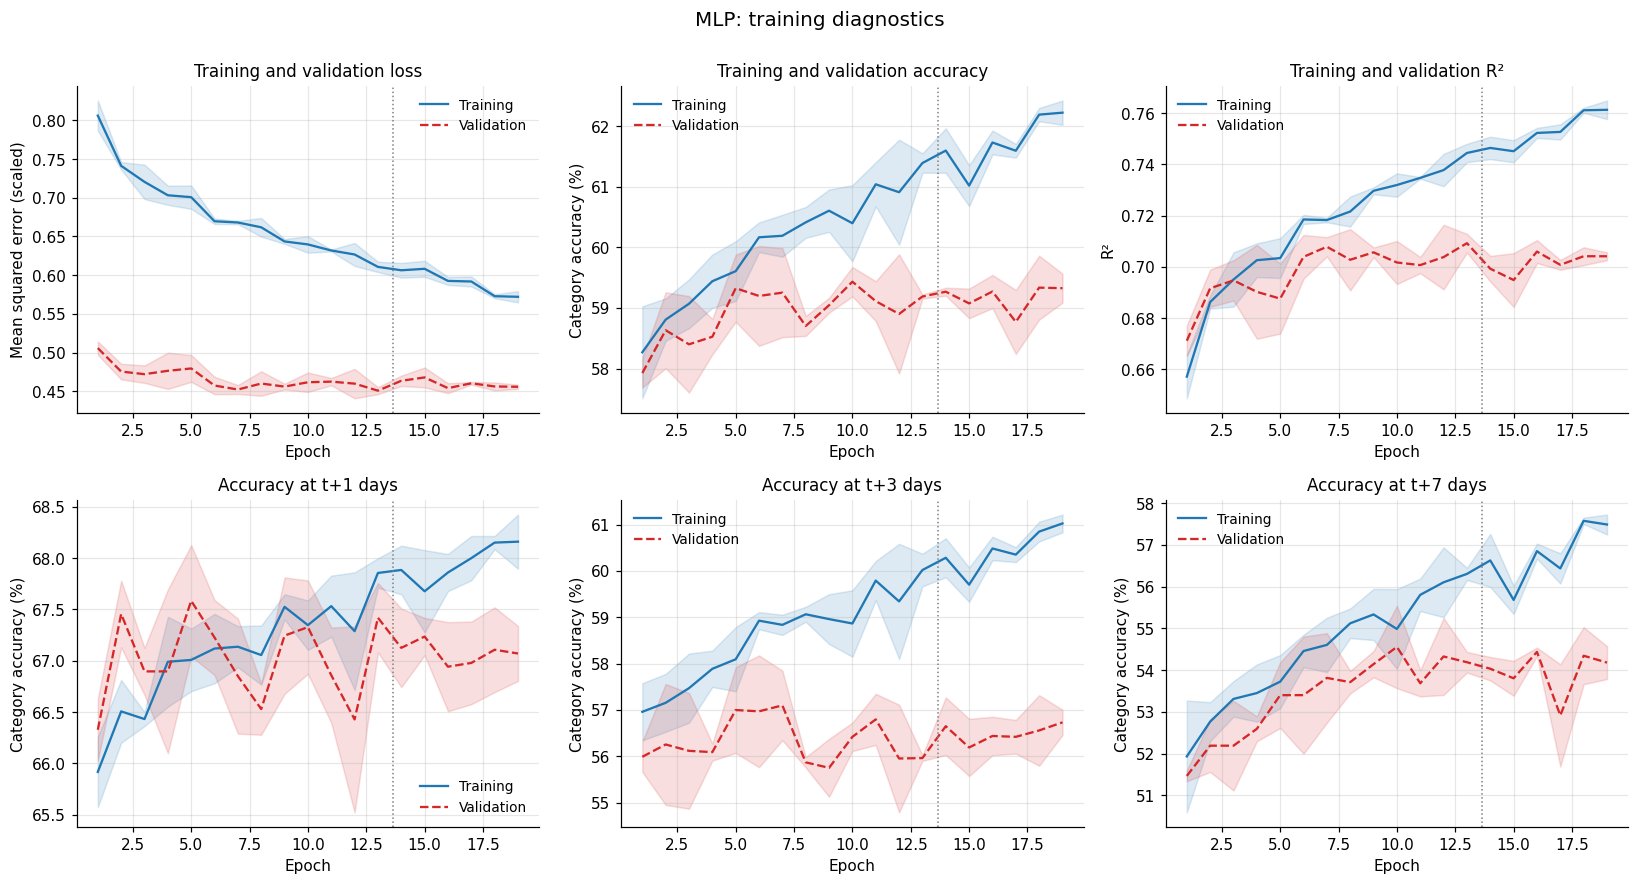

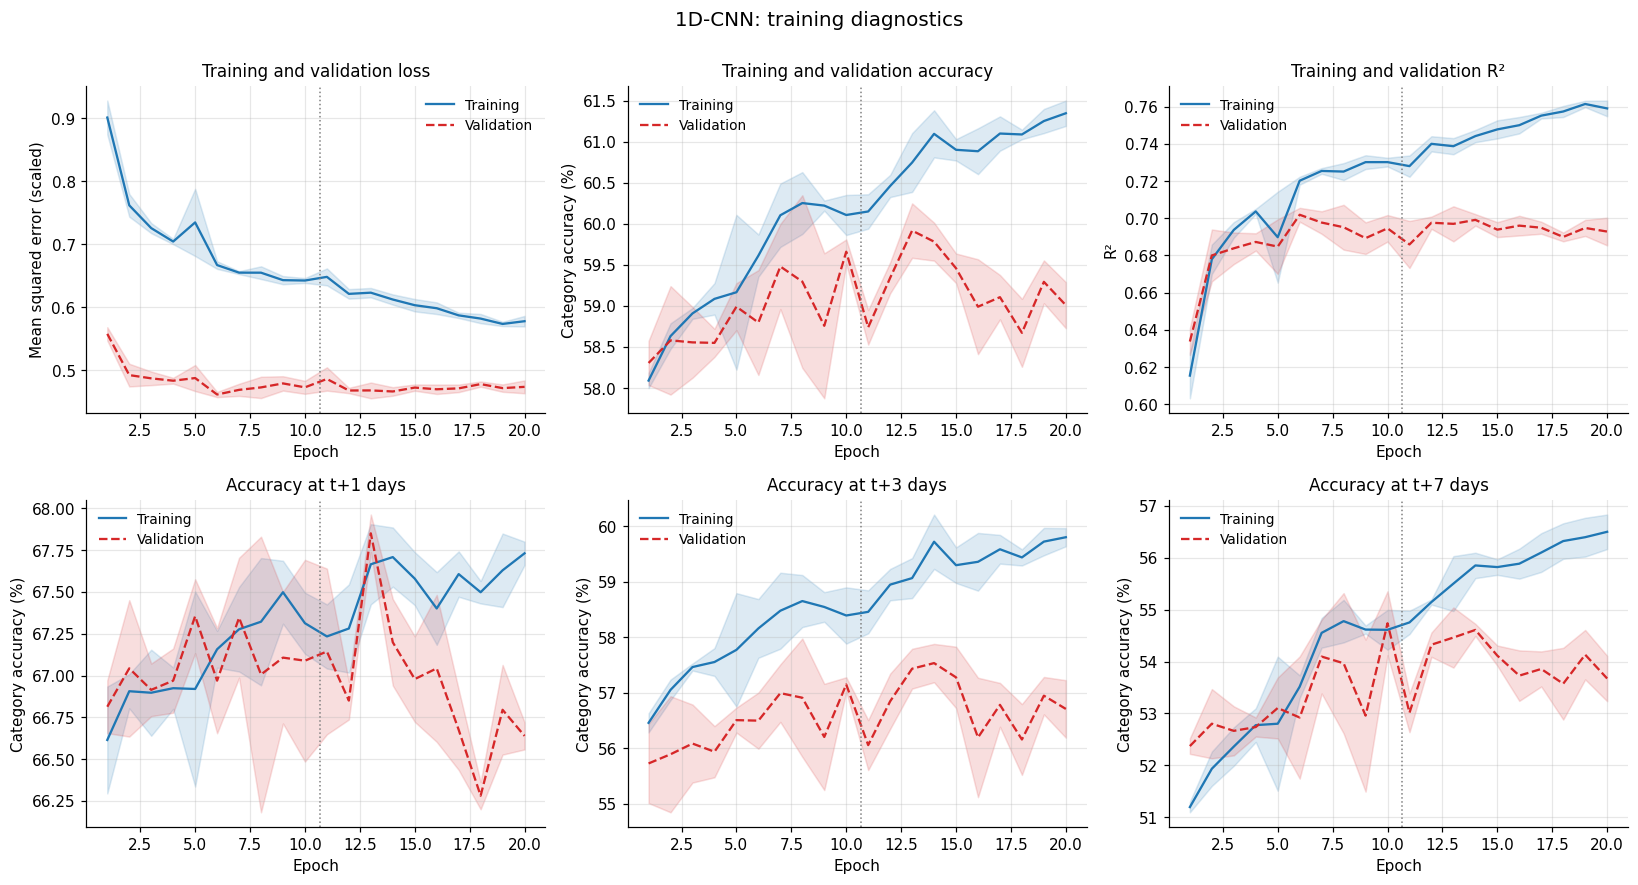

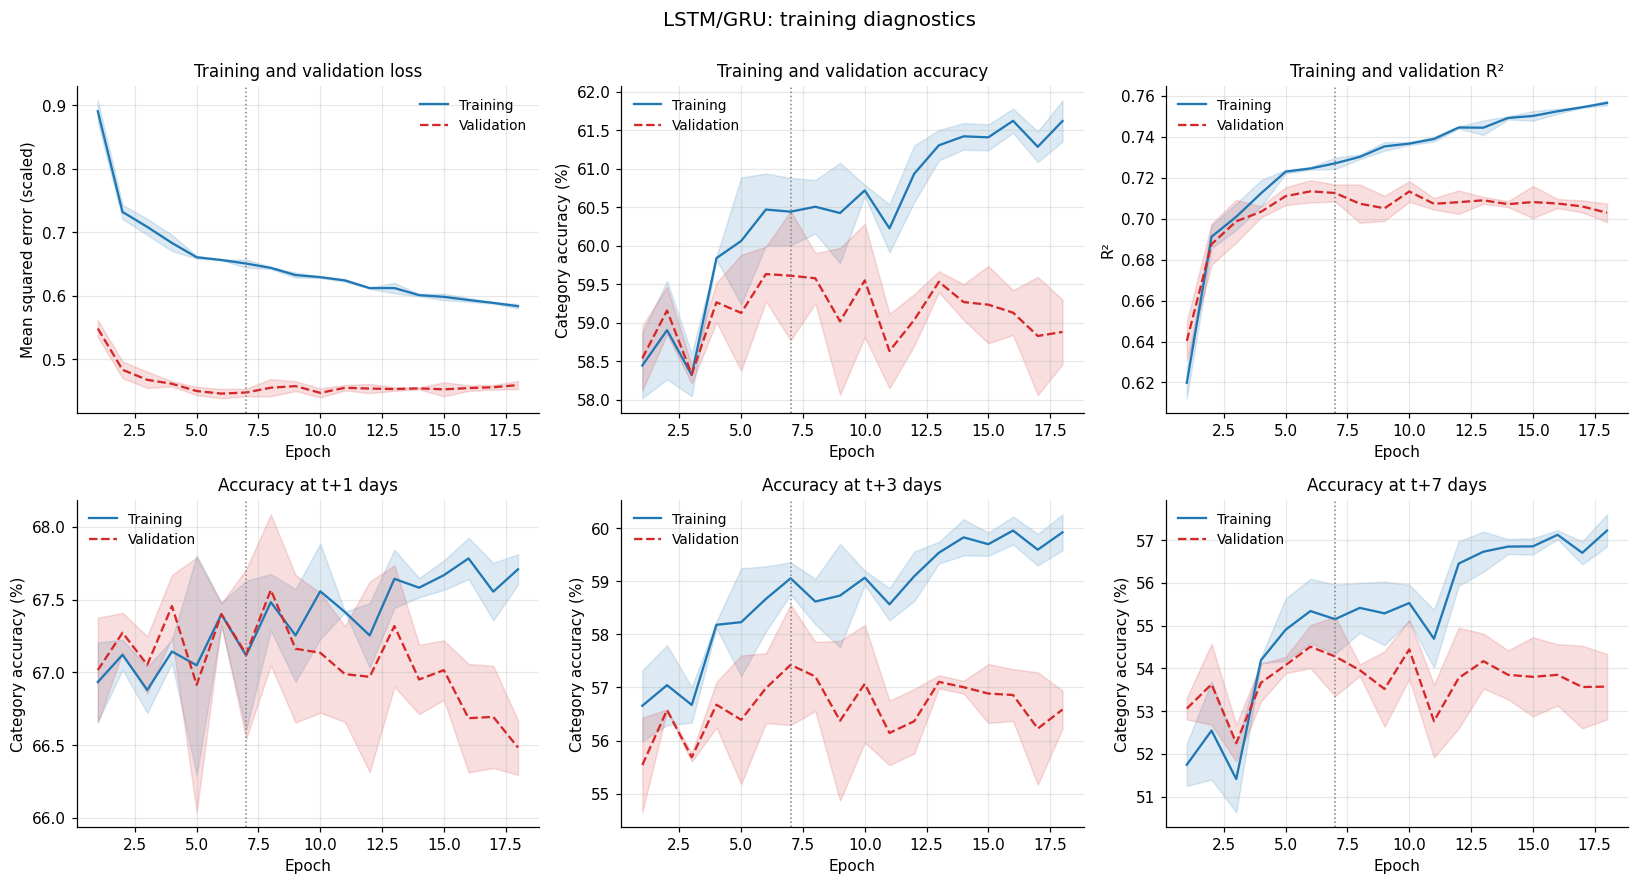

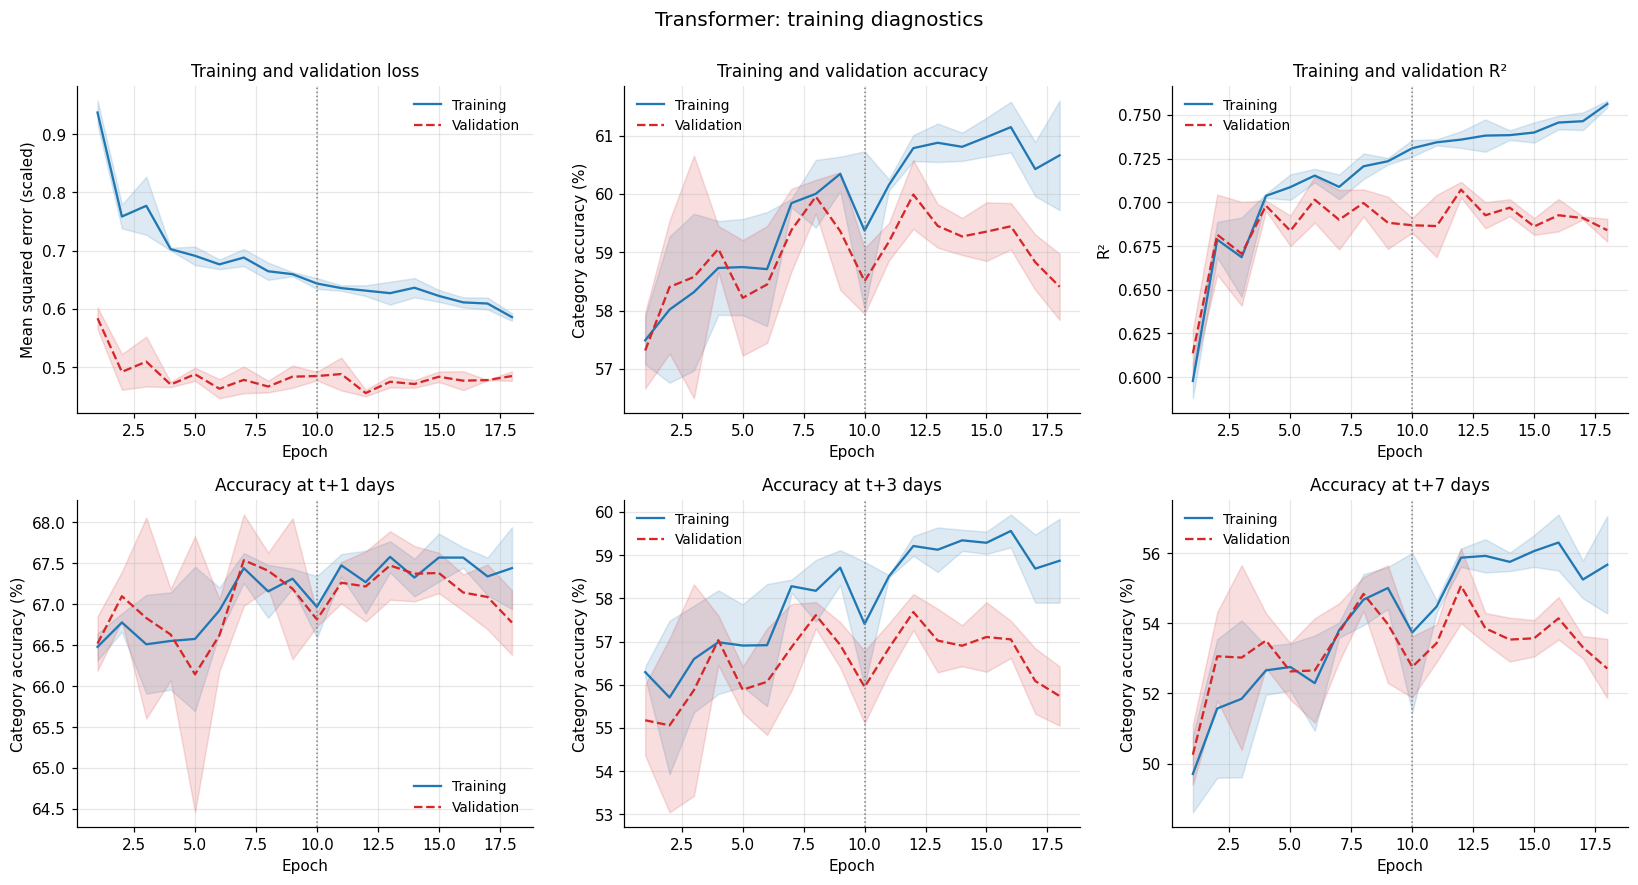

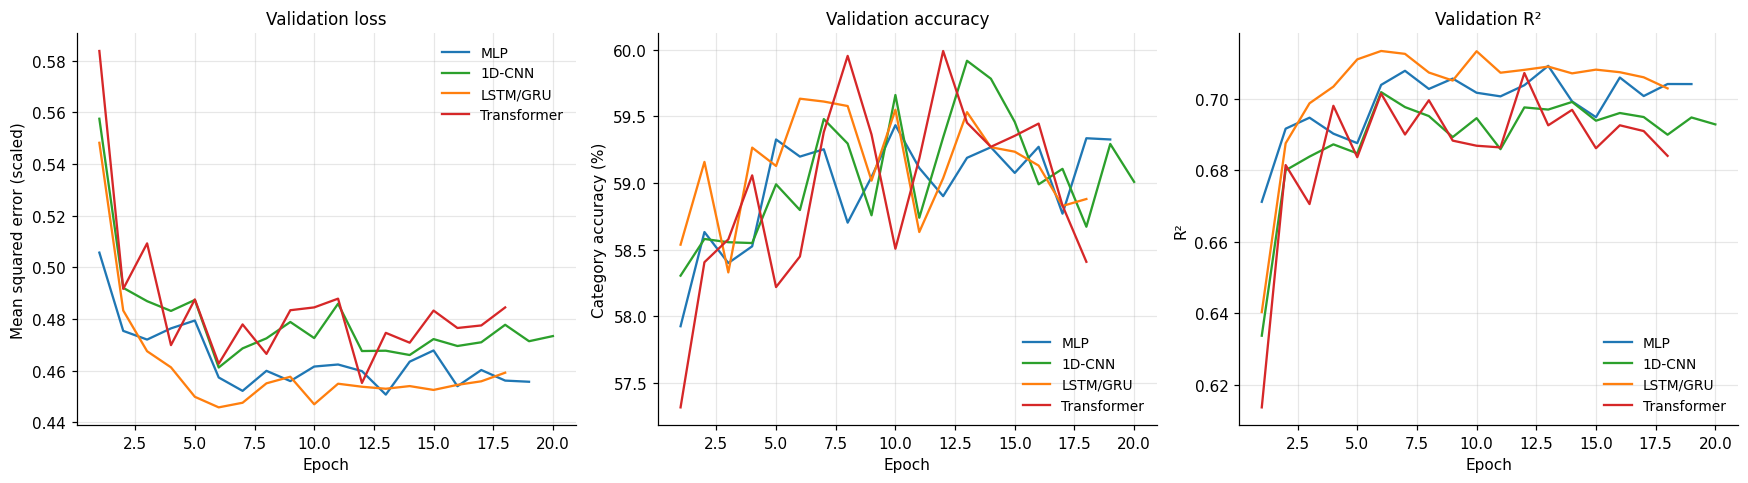

In [14]:
def mean_std(hists, key, n):
    arr = np.stack([np.asarray(h[key][:n]) for h in hists])
    return arr.mean(0), arr.std(0)

def draw_pair(ax, hists, tkey, vkey, n, title, ylabel, best_epoch, j=None):
    ep = np.arange(1, n + 1)
    for key, style, label in [(tkey, "-", "Training"), (vkey, "--", "Validation")]:
        m, s = mean_std(hists, key, n)
        if j is not None:
            m, s = m[:, j], s[:, j]
        color = "#1f77b4" if label == "Training" else "#d62728"
        ax.plot(ep, m, style, color=color, label=label)
        ax.fill_between(ep, m - s, m + s, color=color, alpha=0.15)
    if best_epoch <= n:
        ax.axvline(best_epoch, color="gray", ls=":", lw=1)
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.set_ylabel(ylabel)
    ax.legend()

for name in MODEL_NAMES:
    hs = runs[name]["histories"]
    n = min(len(h["val_loss"]) for h in hs)
    be = float(np.mean(runs[name]["best_epoch"]))
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    draw_pair(axes[0, 0], hs, "train_loss", "val_loss", n, "Training and validation loss", "Mean squared error (scaled)", be)
    draw_pair(axes[0, 1], hs, "train_acc", "val_acc", n, "Training and validation accuracy", "Category accuracy (%)", be)
    draw_pair(axes[0, 2], hs, "train_r2", "val_r2", n, "Training and validation R²", "R²", be)
    for j, h in enumerate(HORIZONS):
        draw_pair(axes[1, j], hs, "train_acc_h", "val_acc_h", n, f"Accuracy at t+{h} days", "Category accuracy (%)", be, j=j)
    fig.suptitle(f"{name}: training diagnostics", fontsize=13, y=1.0)
    finish(fig, f"10_training_{name.replace('/', '_').replace(' ', '_')}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for name in MODEL_NAMES:
    hs = runs[name]["histories"]
    n = min(len(h["val_loss"]) for h in hs)
    for ax, key in zip(axes, ["val_loss", "val_acc", "val_r2"]):
        m, _ = mean_std(hs, key, n)
        ax.plot(np.arange(1, n + 1), m, color=COLORS[name], label=name)
for ax, title, ylabel in zip(axes, ["Validation loss", "Validation accuracy", "Validation R²"],
                             ["Mean squared error (scaled)", "Category accuracy (%)", "R²"]):
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.set_ylabel(ylabel); ax.legend()
finish(fig, "11_validation_comparison")

## 14. Comparative Visualisation

The figures compare test-set error across models and horizons, the agreement between predicted and observed concentrations, and the forecast trajectories for selected cities. Scatter plots and trajectories use predictions averaged over the three seeds.

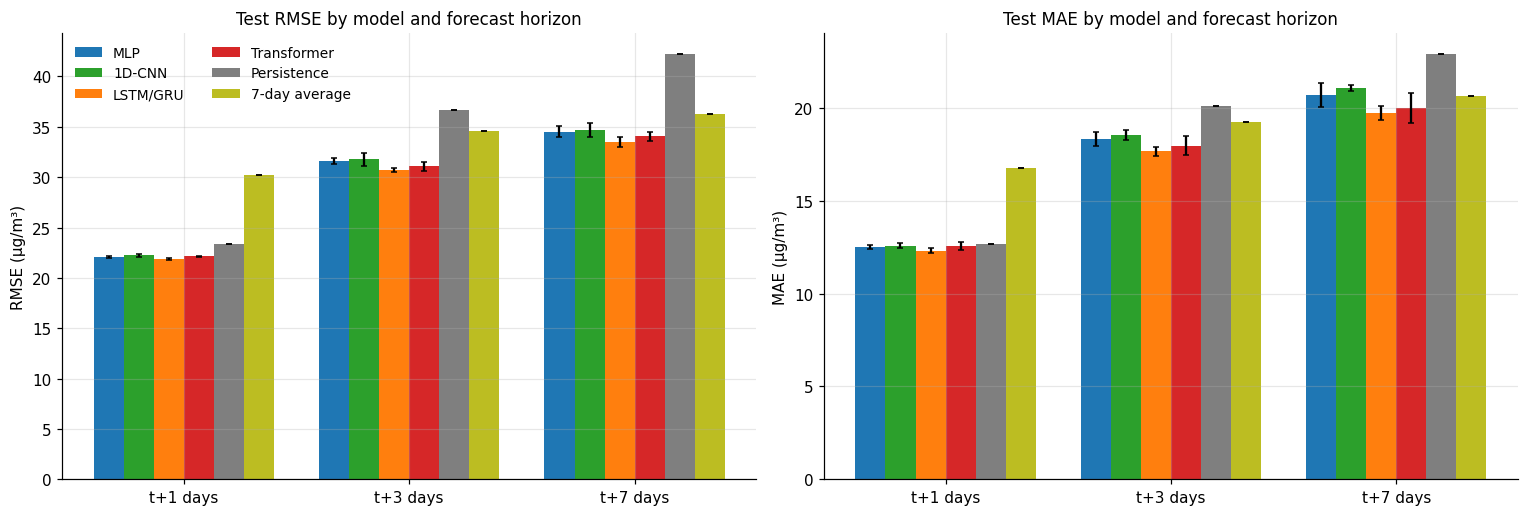

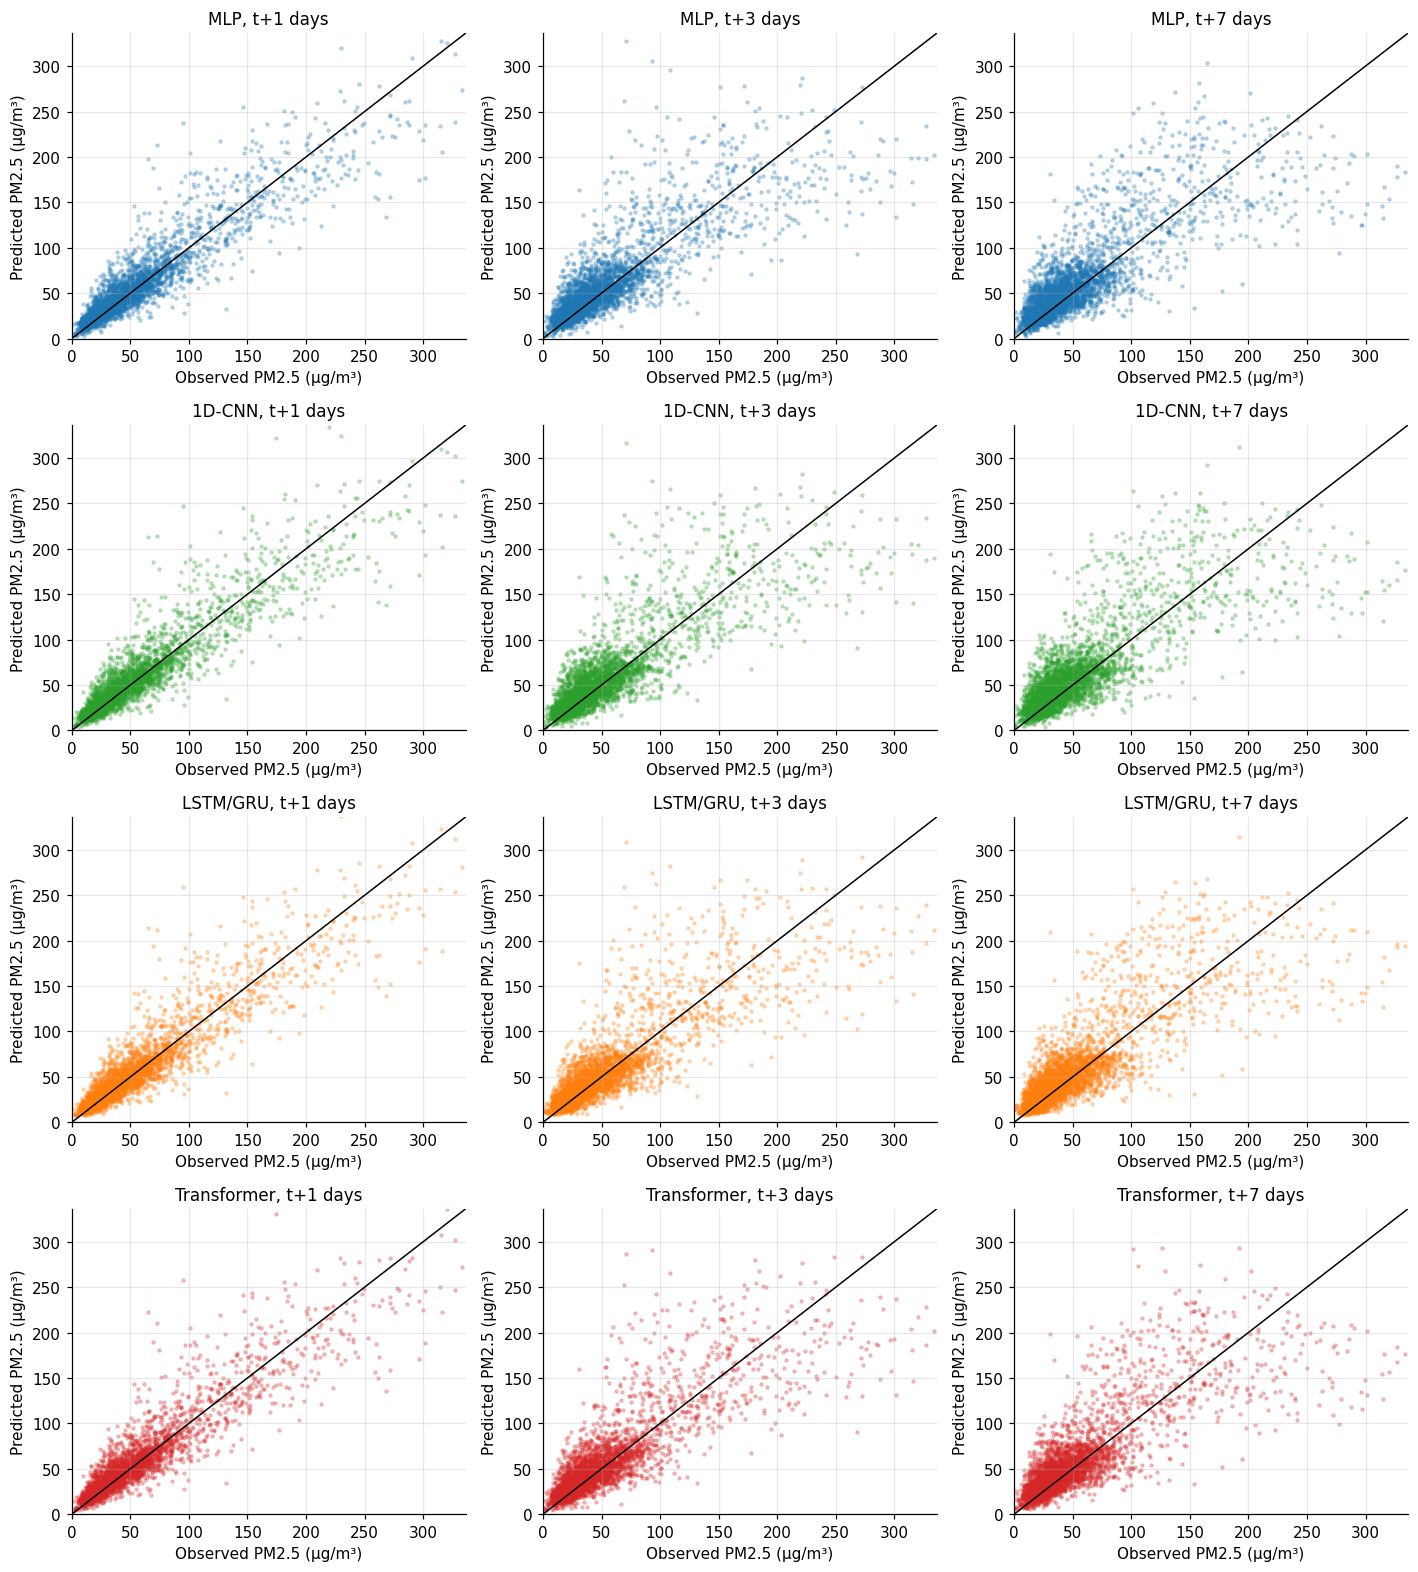

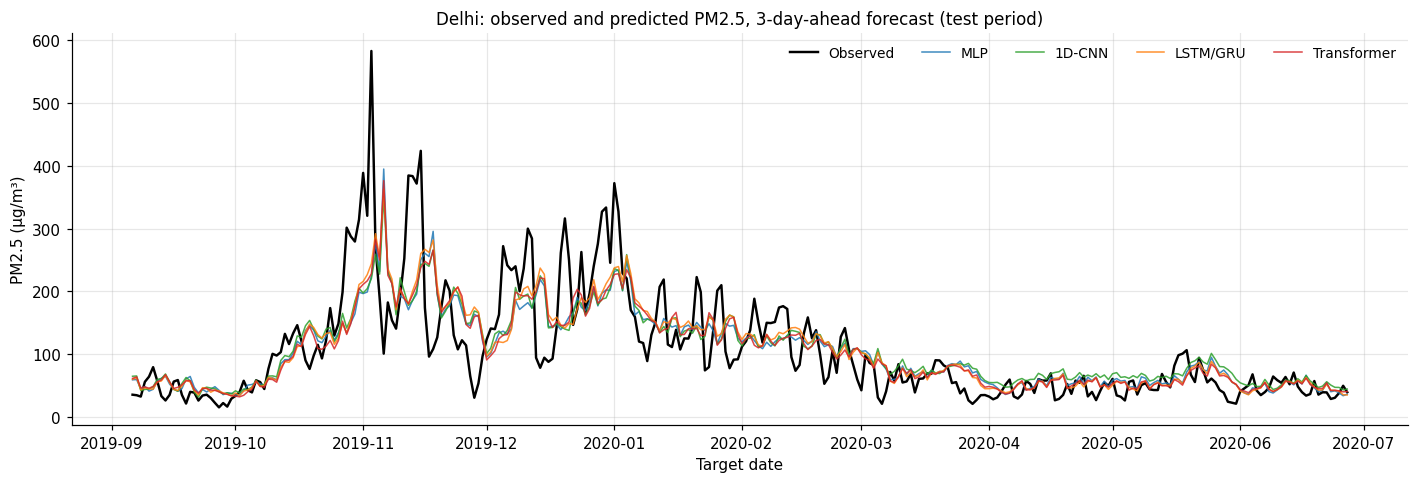

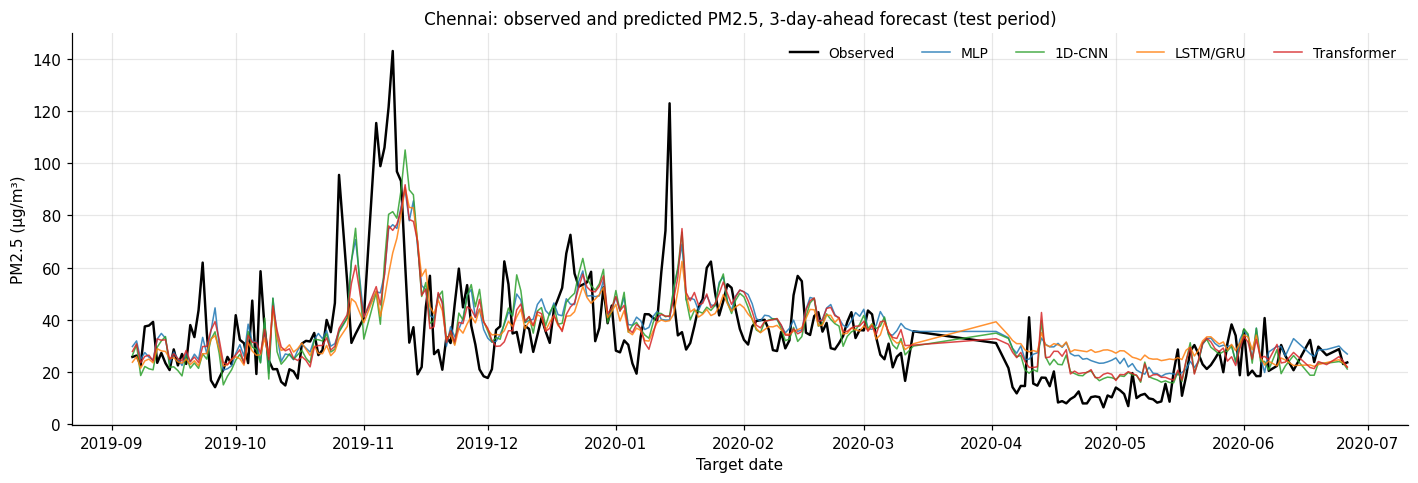

In [15]:
series_names = list(MODEL_NAMES) + list(reference)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, metric, key in [(axes[0], "RMSE", "rmse"), (axes[1], "MAE", "mae")]:
    w = 0.8 / len(series_names)
    for k, n in enumerate(series_names):
        stats_ = row_stats(n)
        m, s = (stats_[0], stats_[1]) if key == "rmse" else (stats_[2], stats_[3])
        ax.bar(np.arange(len(HORIZONS)) + k * w - 0.4 + w / 2, m, w, yerr=s, capsize=2, color=COLORS[n], label=n)
    ax.set_xticks(range(len(HORIZONS))); ax.set_xticklabels([f"t+{h} days" for h in HORIZONS])
    ax.set_ylabel(f"{metric} (µg/m³)"); ax.set_title(f"Test {metric} by model and forecast horizon")
axes[0].legend(ncol=2)
finish(fig, "12_error_by_model_and_horizon")

mean_pred = {n: runs[n]["test_pred"].mean(0) for n in MODEL_NAMES}
y_te = y_abs[te]
lim = float(np.percentile(y_te, 99.5)) * 1.05
fig, axes = plt.subplots(len(MODEL_NAMES), len(HORIZONS), figsize=(13, 3.6 * len(MODEL_NAMES)))
for i, n in enumerate(MODEL_NAMES):
    for j, h in enumerate(HORIZONS):
        ax = axes[i, j]
        ax.scatter(y_te[:, j], mean_pred[n][:, j], s=4, alpha=0.25, color=COLORS[n])
        ax.plot([0, lim], [0, lim], color="black", lw=1)
        ax.set_xlim(0, lim); ax.set_ylim(0, lim)
        ax.set_title(f"{n}, t+{h} days")
        ax.set_xlabel("Observed PM2.5 (µg/m³)"); ax.set_ylabel("Predicted PM2.5 (µg/m³)")
finish(fig, "13_predicted_vs_observed")

te_dates = pd.to_datetime(win_date[te])
te_city = city_id[te]
hj = HORIZONS.index(PLOT_HORIZON)
for city in PLOT_CITIES:
    mask = te_city == city_to_id[city]
    order_ = np.argsort(te_dates[mask])
    target_dates = te_dates[mask][order_] + pd.Timedelta(days=PLOT_HORIZON)
    fig, ax = plt.subplots(figsize=(13, 4.5))
    ax.plot(target_dates, y_te[mask][order_, hj], color=COLORS["Actual"], lw=1.6, label="Observed")
    for n in MODEL_NAMES:
        ax.plot(target_dates, mean_pred[n][mask][order_, hj], color=COLORS[n], lw=1, alpha=0.85, label=n)
    ax.set_title(f"{city}: observed and predicted PM2.5, {PLOT_HORIZON}-day-ahead forecast (test period)")
    ax.set_xlabel("Target date"); ax.set_ylabel("PM2.5 (µg/m³)")
    ax.legend(ncol=5)
    finish(fig, f"14_forecast_{city}")

## 15. Error Analysis

Test RMSE (µg/m³, averaged over the three horizons and the three seeds) is broken down by season, by concentration level, by lockdown period and by city. In the season, lockdown and city analyses, *n* is the number of test windows. In the concentration analysis, *n* is the number of forecast targets.

Seasons are defined as Winter (December to February), Summer (March to May), Monsoon (June to September) and Post-monsoon (October to November). Spike days are days on which the observed PM2.5 exceeds 150 µg/m³. The lockdown analysis separates windows starting on or after 25 March 2020.

,n,MLP,1D-CNN,LSTM/GRU,Transformer,Persistence,7-day average
Winter,1015,32.97,33.67,32.68,32.95,39.78,39.00
Summer,1454,15.82,16.31,14.79,15.00,15.84,15.49
Monsoon,661,12.32,12.32,11.79,11.91,12.92,12.08
Post-monsoon,465,57.49,56.79,56.07,57.09,66.99,67.00


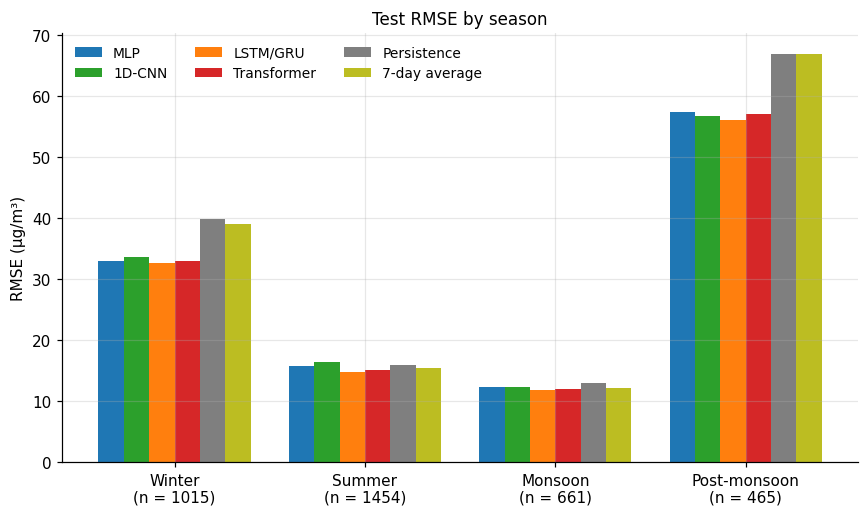

,n,MLP,1D-CNN,LSTM/GRU,Transformer,Persistence,7-day average
Normal days (up to 150),10100,22.16,22.58,21.69,21.82,25.63,25.34
Spike days (above 150),685,79.71,78.96,77.63,79.42,92.56,91.65


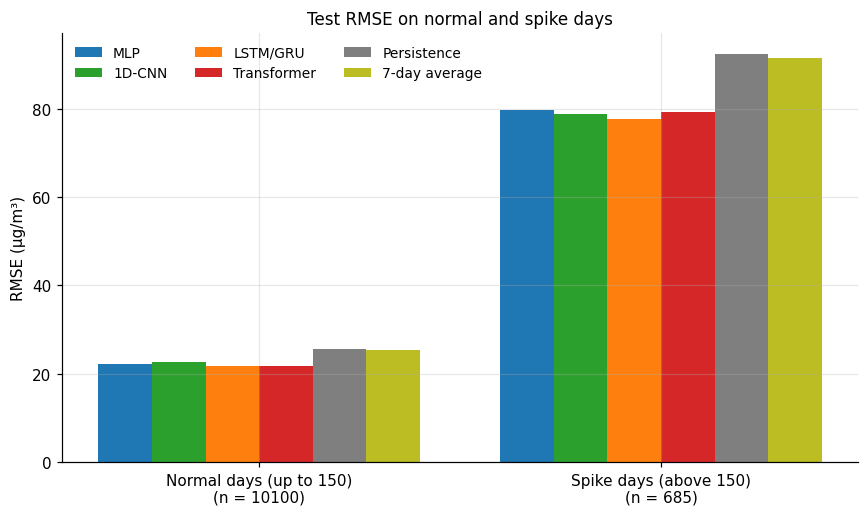

,n,MLP,1D-CNN,LSTM/GRU,Transformer,Persistence,7-day average
Before 25 March 2020,1981,37.67,37.72,36.89,37.42,44.28,43.75
From 25 March 2020,1614,13.51,14.07,12.74,12.87,13.35,13.31


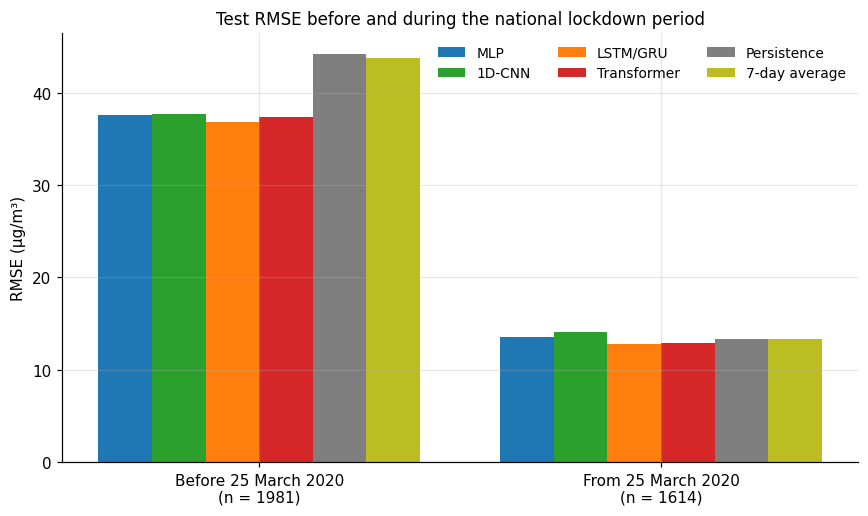

,n,MLP,1D-CNN,LSTM/GRU,Transformer,Persistence,7-day average
Ahmedabad,288,21.21,21.81,20.65,21.28,23.15,22.23
Amaravati,126,8.03,9.58,7.48,7.93,8.95,9.84
Amritsar,159,18.43,17.51,16.69,17.02,18.94,18.12
Bengaluru,292,11.32,12.01,11.27,11.73,13.03,12.96
Chennai,261,16.91,17.09,17.60,16.53,19.92,19.42
Delhi,296,56.51,56.73,55.81,56.05,68.41,68.03
Gurugram,246,54.11,54.27,53.69,53.29,64.15,63.81
Hyderabad,295,11.99,11.81,11.67,11.83,13.52,14.15
Jaipur,162,12.08,12.73,11.87,11.95,13.15,12.79
Kolkata,117,12.61,14.23,11.87,12.80,13.27,12.48


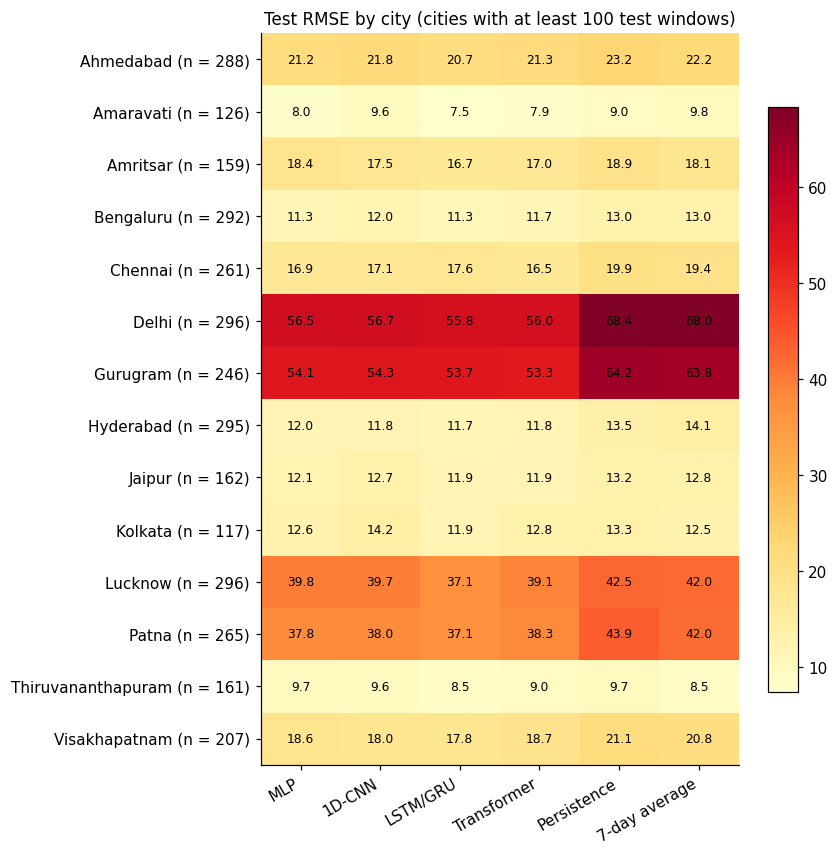

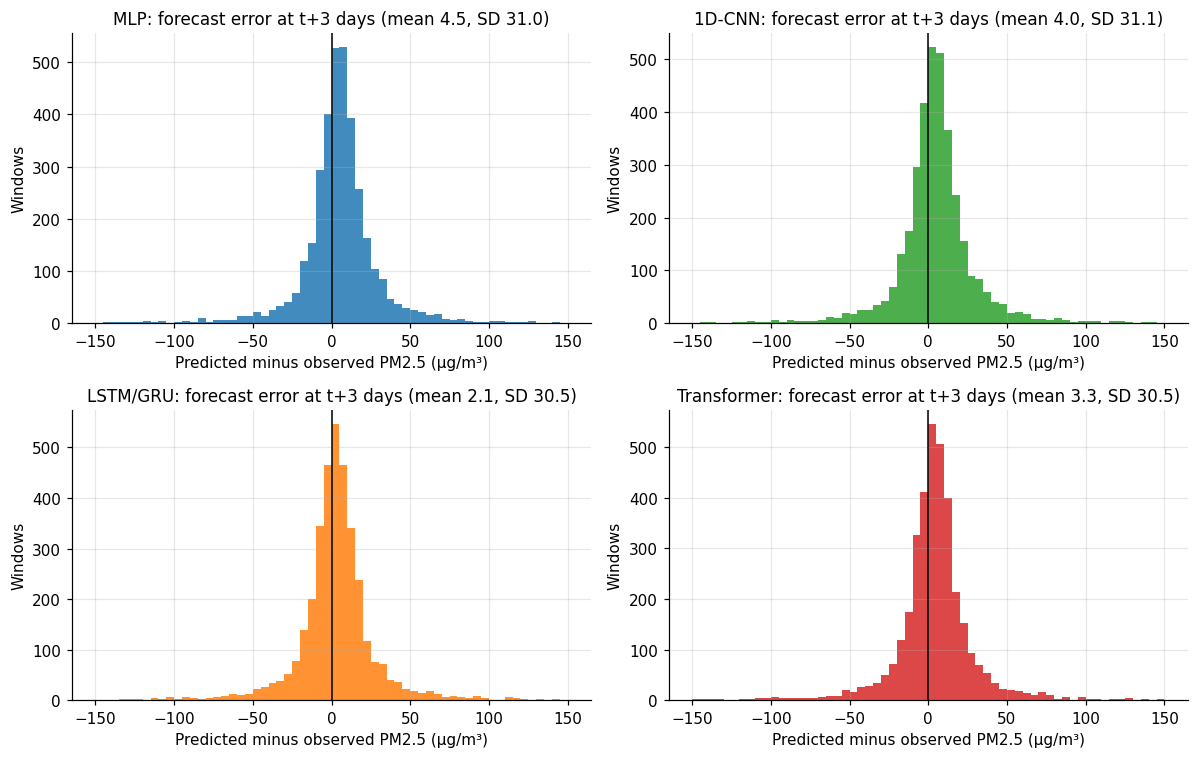

In [16]:
season_of = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Summer", 4: "Summer", 5: "Summer",
             6: "Monsoon", 7: "Monsoon", 8: "Monsoon", 9: "Monsoon", 10: "Post-monsoon", 11: "Post-monsoon"}
te_season = np.array([season_of[m] for m in te_dates.month])

series = {n: runs[n]["test_pred"] for n in MODEL_NAMES}
if INCLUDE_REFERENCE:
    series.update({"Persistence": persist[te][None], "7-day average": avg7[te][None]})

def group_rmse(pred_runs, mask):
    m = np.broadcast_to(mask.reshape(len(mask), -1), y_te.shape)
    vals = []
    for p in pred_runs:
        e = (p - y_te) ** 2
        per_h = [np.sqrt(e[m[:, h], h].mean()) if m[:, h].any() else np.nan for h in range(len(HORIZONS))]
        vals.append(np.nanmean(per_h))
    return float(np.mean(vals))

def group_table(groups):
    out = pd.DataFrame({n: {g: group_rmse(p, m) for g, m in groups.items()} for n, p in series.items()})
    out.insert(0, "n", [int(m.sum()) for m in groups.values()])
    return out

def grouped_bars(df, title, fname):
    cols = [c for c in df.columns if c != "n"]
    fig, ax = plt.subplots(figsize=(max(8, 2.0 * len(df)), 4.8))
    w = 0.8 / len(cols)
    for k, c in enumerate(cols):
        ax.bar(np.arange(len(df)) + k * w - 0.4 + w / 2, df[c].values, w, color=COLORS[c], label=c)
    ax.set_xticks(range(len(df)))
    ax.set_xticklabels([f"{i}\n(n = {int(r)})" for i, r in zip(df.index, df["n"])])
    ax.set_ylabel("RMSE (µg/m³)"); ax.set_title(title)
    ax.legend(ncol=3)
    finish(fig, fname)

season_order = [s for s in ["Winter", "Summer", "Monsoon", "Post-monsoon"] if (te_season == s).any()]
season_df = group_table({s: te_season == s for s in season_order})
display(season_df.round(2))
grouped_bars(season_df, "Test RMSE by season", "15_error_by_season")

spike_df = group_table({f"Normal days (up to {SPIKE_THRESHOLD})": y_te <= SPIKE_THRESHOLD,
                        f"Spike days (above {SPIKE_THRESHOLD})": y_te > SPIKE_THRESHOLD})
display(spike_df.round(2))
grouped_bars(spike_df, "Test RMSE on normal and spike days", "16_error_by_concentration")

lock = np.asarray(te_dates >= pd.Timestamp(LOCKDOWN_START))
lock_df = group_table({"Before 25 March 2020": ~lock, "From 25 March 2020": lock})
display(lock_df.round(2))
grouped_bars(lock_df, "Test RMSE before and during the national lockdown period", "17_error_by_lockdown")

city_counts = pd.Series(te_city).value_counts()
eligible = [c for c in sorted(city_counts.index, key=lambda c: cities[c]) if city_counts[c] >= 100]
city_df = group_table({cities[c]: te_city == c for c in eligible})
display(city_df.round(2))
heat_cols = [c for c in city_df.columns if c != "n"]
fig, ax = plt.subplots(figsize=(8, 0.42 * len(city_df) + 2))
im = ax.imshow(city_df[heat_cols].values, aspect="auto", cmap="YlOrRd")
ax.set_xticks(range(len(heat_cols))); ax.set_xticklabels(heat_cols, rotation=30, ha="right")
ax.set_yticks(range(len(city_df))); ax.set_yticklabels([f"{c} (n = {int(n)})" for c, n in zip(city_df.index, city_df["n"])])
ax.grid(False)
for i in range(len(city_df)):
    for j in range(len(heat_cols)):
        ax.text(j, i, f"{city_df[heat_cols].values[i, j]:.1f}", ha="center", va="center", fontsize=8)
ax.set_title("Test RMSE by city (cities with at least 100 test windows)")
fig.colorbar(im, ax=ax, shrink=0.8)
finish(fig, "18_error_by_city")

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, n in zip(axes.ravel(), MODEL_NAMES):
    err = mean_pred[n][:, hj] - y_te[:, hj]
    ax.hist(err, bins=60, range=(-150, 150), color=COLORS[n], alpha=0.85)
    ax.axvline(0, color="black", lw=1)
    ax.set_title(f"{n}: forecast error at t+{PLOT_HORIZON} days (mean {err.mean():.1f}, SD {err.std():.1f})")
    ax.set_xlabel("Predicted minus observed PM2.5 (µg/m³)"); ax.set_ylabel("Windows")
finish(fig, "19_error_distribution")

## 16. Model Size Sensitivity (Optional)

When enabled (`RUN_SIZE_SENSITIVITY = True` in the configuration), the MLP is retrained at several sizes using the selected hyperparameters, to examine how accuracy depends on the number of parameters. The dashed line marks the 60,000-parameter limit used in the main comparison.

In [17]:
size_df = None
if RUN_SIZE_SENSITIVITY:
    size_rows = []
    for hid in [(8,), (16,), (32, 16), (64, 32), (192, 96), (512, 256), (1024, 512)]:
        cfg = dict(best_cfg["MLP"]); cfg["hidden"] = list(hid)
        n_par = count_params(build_model("MLP", cfg))
        for seed in FINAL_SEEDS:
            res = fit("MLP", cfg, seed)
            pred = predict_concentration(res["model"], "MLP", idx_te)
            size_rows.append({"Hidden layers": str(hid), "Parameters": n_par, "Seed": seed,
                              "Validation RMSE": float(res["val_rmse"].mean()),
                              "Test RMSE": float(error_metrics(y_abs[te], pred)[0].mean())})
            del res
    size_df = pd.DataFrame(size_rows)
    agg = size_df.groupby(["Hidden layers", "Parameters"]).agg(
        val_mean=("Validation RMSE", "mean"), val_std=("Validation RMSE", "std"),
        test_mean=("Test RMSE", "mean"), test_std=("Test RMSE", "std")).reset_index().sort_values("Parameters")
    display(agg.round(2))
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.errorbar(agg["Parameters"], agg["val_mean"], agg["val_std"], marker="o", capsize=3, color="#ff7f0e", label="Validation")
    ax.errorbar(agg["Parameters"], agg["test_mean"], agg["test_std"], marker="s", capsize=3, color="#1f77b4", label="Test")
    ax.axvline(PARAM_CAP, color="gray", ls="--", lw=1, label="Parameter limit")
    ax.set_xscale("log"); ax.set_xlabel("Number of parameters (log scale)")
    ax.set_ylabel("Mean RMSE over horizons (µg/m³)")
    ax.set_title("MLP accuracy as a function of model size")
    ax.legend()
    finish(fig, "20_model_size_sensitivity")
else:
    print("Model size sensitivity analysis is disabled.")

Model size sensitivity analysis is disabled.


## 17. Export of Results

All data files, result tables, predictions, training histories and figures are written to a single archive. In Colab, the download of the archive starts automatically when the next cell finishes. The notebook file itself is not included in the archive.

In [18]:
res_dir = os.path.join(OUT_DIR, "results")

cleaning_log.to_csv(os.path.join(res_dir, "cleaning_log.csv"), index=False)
after_fill.to_csv(os.path.join(res_dir, "missing_values_after_cleaning.csv"))
counts.to_csv(os.path.join(res_dir, "windows_per_city.csv"))
results_numeric.to_csv(os.path.join(res_dir, "model_results_summary.csv"), index=False)
table.to_csv(os.path.join(res_dir, "model_results_table.csv"))
vs_baseline.to_csv(os.path.join(res_dir, "change_vs_mlp_baseline.csv"))
if INCLUDE_REFERENCE:
    gain_ref.to_csv(os.path.join(res_dir, "improvement_over_reference_methods.csv"))
param_table.to_csv(os.path.join(res_dir, "model_parameters_and_training_time.csv"), index=False)
ensemble_df.to_csv(os.path.join(res_dir, "seed_average_results.csv"), index=False)
pd.DataFrame(search_log).to_csv(os.path.join(res_dir, "hyperparameter_search_log.csv"), index=False)
season_df.to_csv(os.path.join(res_dir, "error_by_season.csv"))
spike_df.to_csv(os.path.join(res_dir, "error_by_concentration.csv"))
lock_df.to_csv(os.path.join(res_dir, "error_by_lockdown.csv"))
city_df.to_csv(os.path.join(res_dir, "error_by_city.csv"))
if size_df is not None:
    size_df.to_csv(os.path.join(res_dir, "model_size_sensitivity.csv"), index=False)

per_seed = []
for n in MODEL_NAMES:
    for s_idx, seed in enumerate(FINAL_SEEDS):
        for j, h in enumerate(HORIZONS):
            per_seed.append({"Model": n, "Seed": seed, "Horizon (days)": h,
                             "RMSE": runs[n]["rmse"][s_idx, j], "MAE": runs[n]["mae"][s_idx, j]})
pd.DataFrame(per_seed).to_csv(os.path.join(res_dir, "results_per_seed.csv"), index=False)

hist_rows = []
for n in MODEL_NAMES:
    for s_idx, seed in enumerate(FINAL_SEEDS):
        h = runs[n]["histories"][s_idx]
        for e in range(len(h["val_loss"])):
            row = {"Model": n, "Seed": seed, "Epoch": e + 1, "Learning rate": h["lr"][e],
                   "Train loss": h["train_loss"][e], "Validation loss": h["val_loss"][e],
                   "Train accuracy (%)": h["train_acc"][e], "Validation accuracy (%)": h["val_acc"][e],
                   "Train R2": h["train_r2"][e], "Validation R2": h["val_r2"][e]}
            for j, hz in enumerate(HORIZONS):
                row[f"Train accuracy t+{hz} (%)"] = h["train_acc_h"][e][j]
                row[f"Validation accuracy t+{hz} (%)"] = h["val_acc_h"][e][j]
            hist_rows.append(row)
pd.DataFrame(hist_rows).to_csv(os.path.join(res_dir, "training_history.csv"), index=False)

pred_rows = []
for j, h in enumerate(HORIZONS):
    block = pd.DataFrame({"City": [cities[c] for c in te_city], "Window date": te_dates.date,
                          "Target date": (te_dates + pd.Timedelta(days=h)).date, "Horizon (days)": h,
                          "Observed": y_te[:, j]})
    if INCLUDE_REFERENCE:
        block["Persistence"] = persist[te][:, j]
        block["7-day average"] = avg7[te][:, j]
    for n in MODEL_NAMES:
        block[n] = mean_pred[n][:, j]
    pred_rows.append(block)
pd.concat(pred_rows).to_csv(os.path.join(res_dir, "test_predictions.csv"), index=False)

readme = """DL Project: Multi-Horizon PM2.5 Forecasting for Indian Cities

data/raw/city_day_raw.csv       Original dataset as uploaded
data/clean/clean_daily.csv      Cleaned and gap-filled daily data with split labels
data/clean/pm25_windows.npz     Model-ready windows, targets and split indicators
results/                        Result tables, error analysis, training history and test predictions
figures/                        All figures in PNG format
"""
with open(os.path.join(OUT_DIR, "README.txt"), "w") as f:
    f.write(readme)

zip_path = shutil.make_archive("dlproject_outputs", "zip", root_dir=".", base_dir=OUT_DIR)
n_files = sum(len(fs) for _, _, fs in os.walk(OUT_DIR))
print(f"Archive created: {zip_path} ({os.path.getsize(zip_path) / 1e6:.1f} MB, {n_files} files)")

if IN_COLAB:
    print("Starting download of the archive.")
    files.download(zip_path)

Archive created: /content/dlproject_outputs.zip (9.7 MB, 44 files)
Starting download of the archive.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>